# 04a · Market features and the daily text–market panel (with plot dumps)

One row per **ticker × trading day t** (GME, AMC, BB; 2009–2023). Everything in a row is known by the **close of day t**; the `y_*` columns are outcomes of **day t+1**.

**Market features (day t).** log return, |return|, Parkinson range volatility `park = sqrt(ln(H/L)² / 4ln2)`, 5- and 20-day return volatility, abnormal log volume (vs previous 20 days), gaps to the 5/20/50-day moving averages, MA5/MA20 crossover.

**News features (FNSPID).** A headline dated D (date only) is used for trading day D+1 (`target_date` from 01), so it sits in the row of the trading day before that. Daily: count, sentiment = mean(p_bull − p_bear), clarity = mean|p_bull − p_bear|, ambiguity = normalised entropy of the mean distribution. Two versions: `nb_` = BiLSTM (03b), `nl_` = LLM teacher (03a).

**Reddit features (r/wallstreetbets, 2020–21).** Comment time converted to New York time; comments after the 16:00 close (or on non-trading days) go to the next trading day. Same metrics (`rd_`), plus upvote-weighted sentiment.

**QISS (Quantified Investor Sentiment Score).** x = sentiment × (1 − ambiguity) × log(1 + n), i.e. direction × conviction × attention, standardised per ticker with an **expanding, past-only** mean and sd. `qiss` = average of news and Reddit QISS where available.

**Targets (day t+1).** `y_log_park` (log range volatility), `y_abn_logvol` (abnormal log volume), `y_abs_ret`, `y_ret`, `y_above_ma20`.

**Sentiment model.** `SENT_VERSION` in the setup cell picks the BiLSTM scores: `v1` (03b) or `v2_reddit` (03d, rolling validation + Reddit labels, default).

**Output.** `Plots/{ticker}_{sent_metric}_vs_{market_metric}_{freq}_{date_range}.png`

In [1]:
# 0. Setup
from google.colab import drive
drive.mount('/content/drive')
import os, glob, numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

def find_project_dir(name="dl-quant_project"):
    cands = [f"/content/drive/MyDrive/Colab Notebooks/{name}", f"/content/drive/MyDrive/{name}",
             *glob.glob(f"/content/drive/MyDrive/*/{name}"), *glob.glob(f"/content/drive/Shareddrives/*/{name}")]
    for p in cands:
        if os.path.isdir(p): return p
    raise FileNotFoundError("Add a shortcut to the shared 'dl-quant_project' folder in My Drive (see 00_START_HERE).")
PROJECT_DIR = find_project_dir(); DATA_DIR = os.path.join(PROJECT_DIR, "DataSource")
pd.set_option("display.width", 200)
SENT_VERSION = "v2_reddit"   # "v1" = 03b BiLSTM; "v2_rolling" / "v2_reddit" = 03d BiLSTM
print("Data folder:", DATA_DIR, "| sentiment model:", SENT_VERSION)

MessageError: Error: credential propagation was unsuccessful

## 0. Common Functions we needed

In [ ]:
# Maps each text/news item to the previous available trading day,
# ensuring information is assigned only to the appropriate prior trading-day information set.
def row_day_for_target(ticker, target):
    # news dated D is used for target trading day T (from 01); it belongs to the info set of the trading day before T
    d = days[ticker]; pos = np.searchsorted(d, np.datetime64(target), side="left")
    return pd.Timestamp(d[pos - 1]) if 0 < pos <= len(d) else pd.NaT

# Aggregates text-level sentiment predictions by ticker and date,
# calculating sentiment direction, conviction (clarity), text volume,
# and normalized sentiment ambiguity using prediction entropy.
def text_agg(df, bearish_col, neutral_col, bullish_col, prefix):
    # Step 1: Calculate sentiment direction for each text item
    # Positive = bullish; Negative = bearish
    df = df.copy()
    df["sentiment"] = df[bullish_col] - df[bearish_col]
    df["clarity"] = df["sentiment"].abs()

    # Step 2: Group text items by ticker and date
    grouped = df.groupby(["ticker", "day"])

    # Step 3: Calculate daily average sentiment, clarity, and text volume
    result = grouped.agg(
        **{
            f"{prefix}n": ("sentiment", "size"),
            f"{prefix}sent": ("sentiment", "mean"),
            f"{prefix}clar": ("clarity", "mean"),
            "bearish_prob": (bearish_col, "mean"),
            "neutral_prob": (neutral_col, "mean"),
            "bullish_prob": (bullish_col, "mean"),
        }
    )

    # Step 4: Calculate normalized entropy to measure sentiment ambiguity
    probabilities = result[
        ["bearish_prob", "neutral_prob", "bullish_prob"]
    ].to_numpy()

    probabilities = np.clip(probabilities, 1e-9, 1)

    result[f"{prefix}amb"] = (
        -(probabilities * np.log(probabilities)).sum(axis=1)
        / np.log(3)
    )

    # Step 5: Clean up intermediate columns and return the results
    result = result.drop(
        columns=["bearish_prob", "neutral_prob", "bullish_prob"]
    )

    return (
        result.reset_index()
        .rename(columns={"day": "date"})
    )


def qiss(g, prefix, min_obs=60):#reddit with less data, min_obs need to be reduced to 20
    # Raw sentiment signal: direction × conviction × attention
    sentiment_signal = (
        g[f"{prefix}sent"]
        * (1 - g[f"{prefix}amb"])
        * g[f"{prefix}logn"]
    )

    # Expanding historical baseline (exclude current observation)
    historical = sentiment_signal.shift(1)
    historical_mean = historical.expanding(min_periods=min_obs).mean()
    historical_std = historical.expanding(min_periods=min_obs).std()

    # Past-only standardized sentiment, clipped to limit outliers
    qiss_score = (sentiment_signal - historical_mean) / historical_std

    return qiss_score.clip(-10, 10)

In [ ]:
## The following selected financial indicators are indlcued
metric_titles = {
    # Financial indicators
    'adj_close': 'Adjusted Closing Price',
    'close': 'Closing Price',
    'volume': 'Trading Volume',
    'ret': 'Daily Log Return',
    'abs_ret': 'Absolute Daily Log Return',
    'park': 'Daily Parkinson Volatility',
    'gk_vol': 'Annualized Garman–Klass Volatility',
    'rv_5d': 'Annualized 5-Day Realized Volatility',
    'logvol': 'Log Daily Trading Volume',
    'abn_logvol': 'Abnormal Log Volume (Relative to Previous 20 Days)',
    'y_ret': 'Next-Day Log Return',
    'y_abs_ret': 'Next-Day Absolute Log Return',
    'y_park_vol': 'Next-Day Annualized Parkinson Volatility',
    'y_logvol_1d': 'Next-Day Log Trading Volume',

    # News indicators
    'nb_n': 'Number of News Articles',
    'nb_sent': 'News Articles Average Sentiment',
    'nb_clar': 'News Articles Average Clarity',
    'nb_amb': 'News Articles Average Ambiguity',
    'nb_qiss': 'Quantified Investor Sentiment Score from News Articles',

    # Reddit indicators
    'rd_n': 'Number of r/wallstreetbets Comments',
    'rd_sent': 'r/wallstreetbets Average Sentiment',
    'rd_clar': 'r/wallstreetbets Average Clarity',
    'rd_amb': 'r/wallstreetbets Average Ambiguity',
    'rd_qiss': 'Quantified Investor Sentiment Score from r/wallstreetbets Comments',
}

## A: Get the Sentiment Scores

In [ ]:
#Take version "v2_reddit" where calibrated Qwen2.5-7B model was used
## Load sentiment features from News articles comments
FN_FILE = "bilstm_scores_fnspid.csv" if SENT_VERSION == "v1" else f"bilstm_{SENT_VERSION}_scores_fnspid.csv"
B = pd.read_csv(os.path.join(DATA_DIR, FN_FILE), parse_dates=["date", "target_date"])
if SENT_VERSION != "v1": B = B.rename(columns={"b2_pbear": "b_pbear", "b2_pneu": "b_pneu", "b2_pbull": "b_pbull"})
days = {t: np.array(sorted(g.date.values)) for t, g in B.groupby("ticker")}

B["day"] = [row_day_for_target(t, T) for t, T in zip(B.ticker, B.target_date)]
B = B.dropna(subset=["day"])

news_b = text_agg(B, "b_pbear", "b_pneu", "b_pbull", "nb_")      # BiLSTM
print("news ticker-days:", len(news_b), "| articles mapped:", len(B))
print(news_b.columns)

news ticker-days: 3570 | articles mapped: 8784
Index(['ticker', 'date', 'nb_n', 'nb_sent', 'nb_clar', 'nb_amb'], dtype='object')


In [ ]:
# ADD ---- QISS -----------------------------------------------------------------
news_b["nb_logn"] = np.log1p(news_b["nb_n"])

news_b = news_b.sort_values(["ticker", "date"]).reset_index(drop=True)

news_b["nb_qiss"] = pd.concat([
    qiss(g, "nb_", min_obs=60)
    for _, g in news_b.groupby("ticker", sort=False)
]).sort_index()

# ---- diagnostics ----------------------------------------------------------
print("News ticker-days:", len(news_b), "| articles mapped:", len(B))
print(B.groupby("ticker").date.agg(["min", "max", "count"]))
print(news_b.columns)

News ticker-days: 3570 | articles mapped: 8784
              min        max  count
ticker                             
AMC    2011-07-01 2023-12-12   3027
BB     2009-10-25 2023-12-16   1071
GME    2009-10-27 2023-12-13   4686
Index(['ticker', 'date', 'nb_n', 'nb_sent', 'nb_clar', 'nb_amb', 'nb_logn', 'nb_qiss'], dtype='object')


In [ ]:
## Load sentiment features from Reddit comments
Rr = pd.read_csv(os.path.join(DATA_DIR, "bilstm_scores_reddit.csv" if SENT_VERSION == "v1" else f"bilstm_{SENT_VERSION}_scores_reddit.csv"))
et = pd.to_datetime(Rr.created_utc, unit="s", utc=True).dt.tz_convert("America/New_York")
cand = et.dt.normalize().dt.tz_localize(None) + pd.to_timedelta((et.dt.hour >= 16).astype(int), unit="D")
Rr["day"] = pd.NaT
for t in Rr.ticker.unique():
    m = (Rr.ticker == t).to_numpy(); d = days[t]
    pos = np.searchsorted(d, cand[m].values.astype("datetime64[ns]"), side="left")
    ok = pos < len(d)
    vals = np.full(m.sum(), np.datetime64("NaT", "ns"), dtype="datetime64[ns]"); vals[ok] = d[pos[ok]]
    Rr.loc[m, "day"] = vals
Rr = Rr.dropna(subset=["day"]); Rr["day"] = pd.to_datetime(Rr.day)
red = text_agg(Rr, "p_bear", "p_neu", "p_bull", "rd_")
w = np.log1p(Rr.score.clip(lower=0)) + 1
Rr["_sw"] = (Rr.p_bull - Rr.p_bear) * w; Rr["_w"] = w
sw = Rr.groupby(["ticker", "day"]).agg(_sw=("_sw", "sum"), _w=("_w", "sum")).reset_index().rename(columns={"day": "date"})
red = red.merge(sw[["ticker", "date"]], on=["ticker", "date"], how="left")
print("reddit ticker-days:", len(red));
print(red.groupby("ticker").agg(first=("date", "min"), last=("date", "max"), days=("date", "count"), comments=("rd_n", "sum")))
print(red.columns)

reddit ticker-days: 277
            first       last  days  comments
ticker                                      
AMC    2021-01-25 2021-07-05   119    296687
BB     2020-12-01 2021-06-21    75    176069
GME    2021-01-03 2021-04-12    83    440228
Index(['ticker', 'date', 'rd_n', 'rd_sent', 'rd_clar', 'rd_amb'], dtype='object')


In [ ]:
# ---- QISS (per ticker, date-ordered, take 10 observation days) --------------------------------------
red = red.sort_values(["ticker", "date"]).reset_index(drop=True)
red["rd_logn"] = np.log1p(red.rd_n)

parts = [qiss(g, "rd_",min_obs=10) for _, g in red.groupby("ticker", sort=False)]
red["rd_qiss"] = pd.concat(parts).reindex(red.index)

# ---- diagnostics ----------------------------------------------------------
print("reddit ticker-days:", len(red))
print(red.groupby("ticker").agg(first=("date", "min"), last=("date", "max"),
                                days=("date", "count"), comments=("rd_n", "sum")))
print(red.columns)

reddit ticker-days: 277
            first       last  days  comments
ticker                                      
AMC    2021-01-25 2021-07-05   119    296687
BB     2020-12-01 2021-06-21    75    176069
GME    2021-01-03 2021-04-12    83    440228
Index(['ticker', 'date', 'rd_n', 'rd_sent', 'rd_clar', 'rd_amb', 'rd_logn', 'rd_qiss'], dtype='object')


## Aa: Get the Sentiment Features

### Useful functions

In [ ]:
## Standardize the plotting function
def plot_coverage(
    df,
    freq="ME",
    start=None,
    end=None,
    columns=("nb_n", "nb_sent", "nb_clar", "nb_amb"),
    tickers=("AMC", "BB", "GME")
):

    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])

    # Select date range
    if start:
        df = df[df["date"] >= start]

    if end:
        df = df[df["date"] <= end]

    # Frequency labels
    freq_titles = {
        "D": "Daily",
        "W": "Weekly",
        "ME": "Monthly"
    }

    period = freq_titles[freq]

    # Aggregation rules
    agg_dict = {
        col: "sum" if col.endswith("_n") else "mean"
        for col in columns
    }

    coverage = (
        df.set_index("date")
        .groupby("ticker")
        .resample(freq)
        .agg(agg_dict)
        .reset_index()
    )

    # Original titles
    titles = {
        "nb_n": f"{period} Number of News Articles",
        "nb_sent": f"{period} Average Sentiment",
        "nb_clar": f"{period} Average Clarity",
        "nb_amb": f"{period} Average Ambiguity",
        "rd_n": f"{period} Number of r/wallstreetbets Comments",
        "rd_sent": f"{period} Average Sentiment",
        "rd_clar": f"{period} Average Clarity",
        "rd_amb": f"{period} Average Ambiguity",
        "nb_qiss": f"{period} Quantified Investor Sentiment Score from News Articles",
        "rd_qiss": f"{period} Quantified Investor Sentiment Score from r/wallstreetbets Comments"
    }

    # Plot
    ncols = 2
    nrows = (len(columns) + ncols - 1) // ncols

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(15, 4.5 * nrows),
        sharex=True,
        squeeze=False
    )

    for ax, col in zip(axes.flat, columns):

        for ticker in tickers:
            data = coverage[coverage["ticker"] == ticker]

            ax.plot(
                data["date"],
                data[col],
                label=ticker,
                linewidth=1.8
            )

        ax.set_title(titles.get(col, f"{period} {col}"))
        ax.set_xlabel("Date")
        ax.set_ylabel(col)
        ax.legend()
        ax.grid(alpha=0.3)

    # Hide unused panels
    for ax in axes.flat[len(columns):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

    return coverage

### Plot dump

#### News Articles

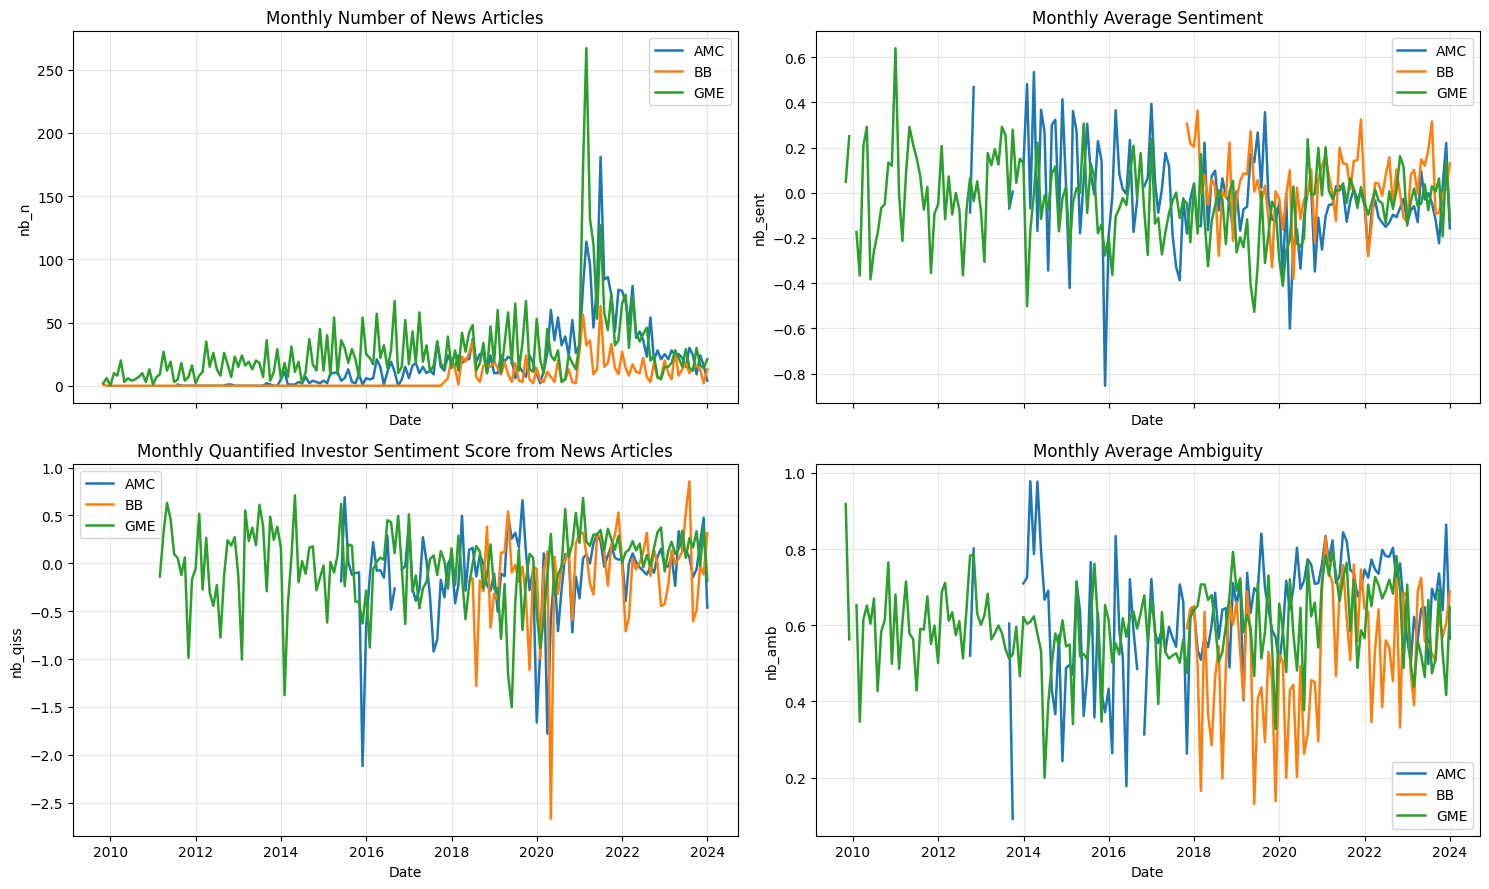

In [ ]:
## Monthly news
newsSent = plot_coverage(
    news_b,
    freq="ME",
    start="2009-01-01",
    end="2024-12-31",
    columns=["nb_n", "nb_sent", "nb_qiss",  "nb_amb"]
)

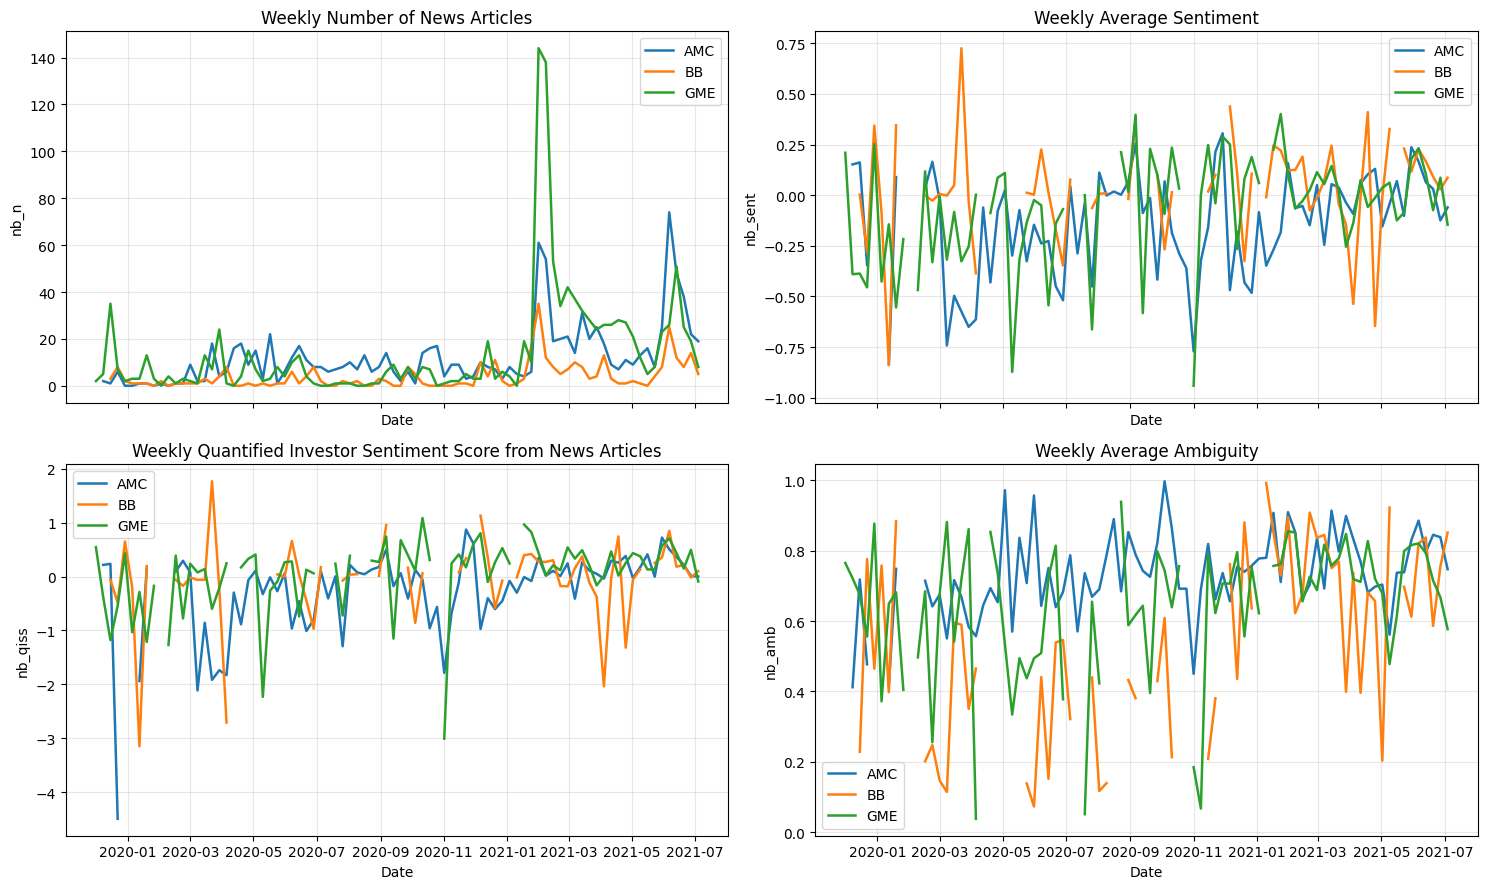

In [ ]:
## Weekly news
newsSent = plot_coverage(
    news_b,
    freq="W",
    start="2019-12-01",
    end="2021-7-1",
    columns=["nb_n", "nb_sent", "nb_qiss",  "nb_amb"]
)

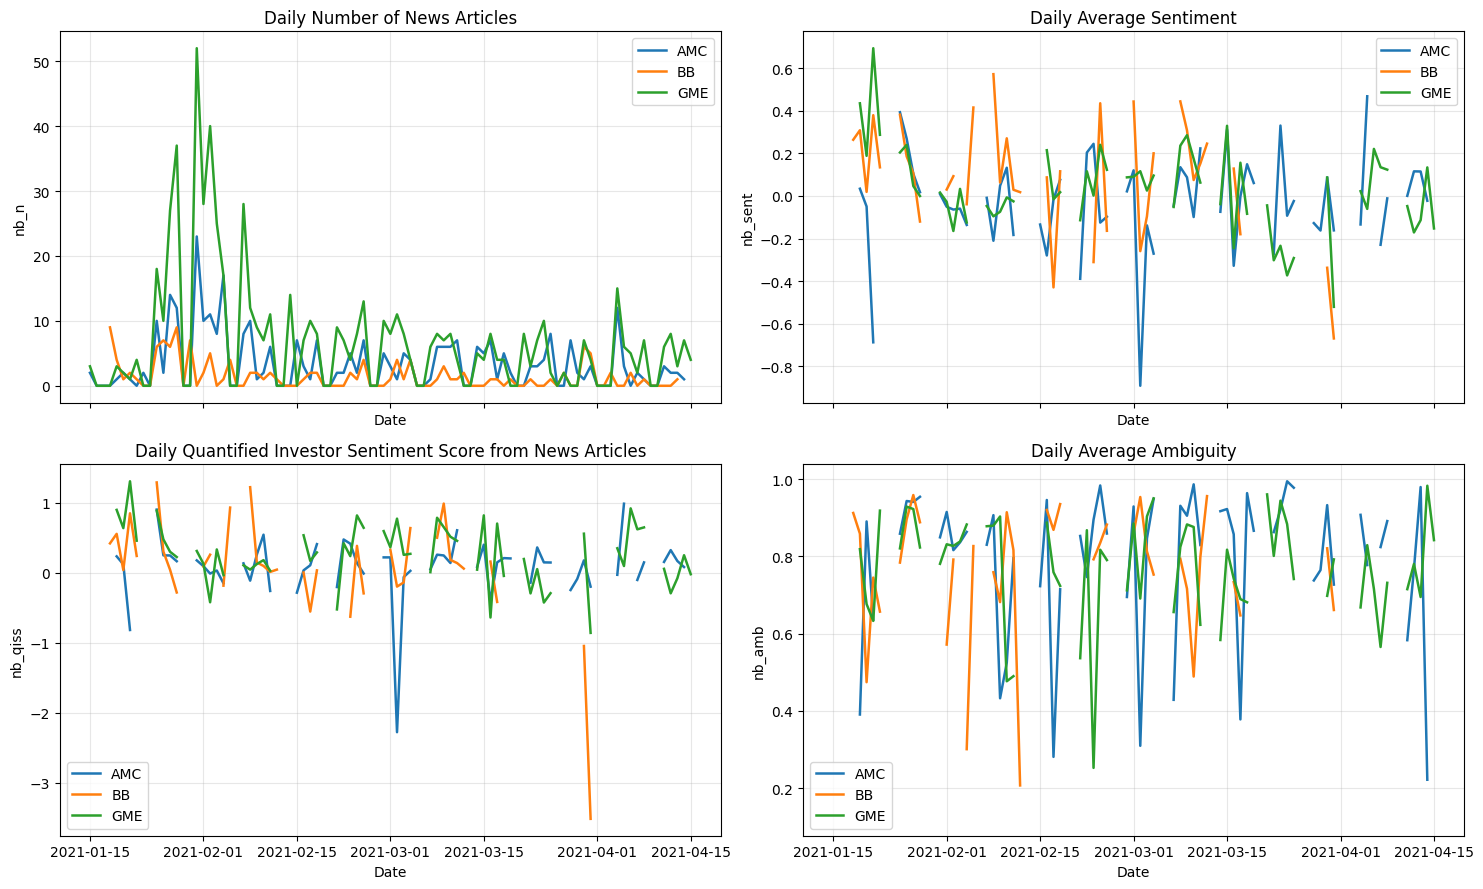

In [ ]:
## Daily news
newsSent = plot_coverage(
    news_b,
    freq="D",
    start="2021-1-15",
    end="2021-4-15",
    columns=["nb_n", "nb_sent","nb_qiss", "nb_amb"]
)

#### Reddit Comments

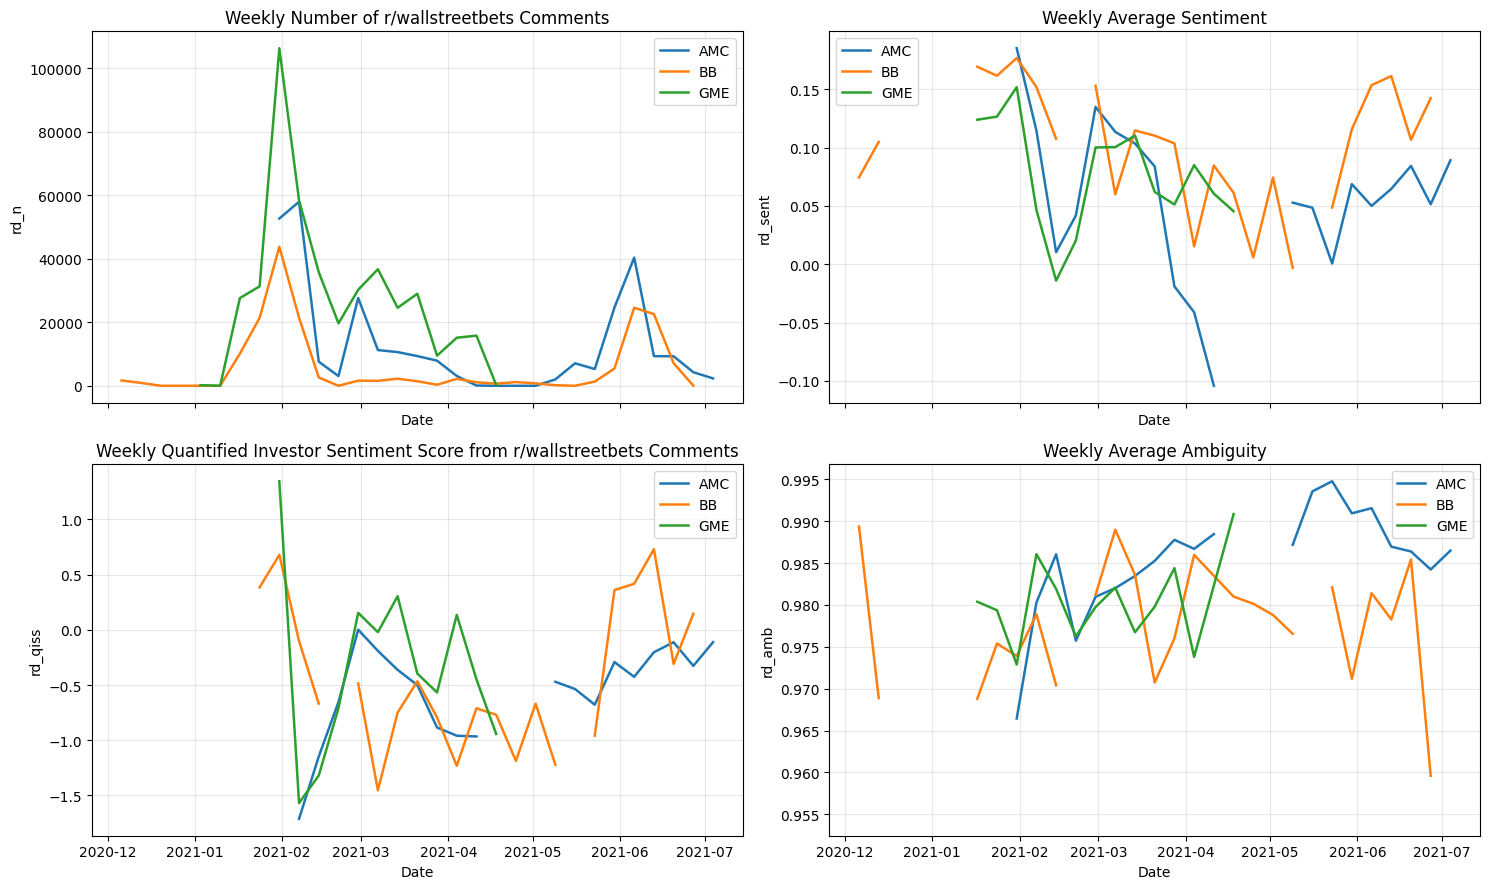

In [ ]:
## Reddit Daily news
newsSent = plot_coverage(
    red,
    freq="W",
    start="2019-12-01",
    end="2021-7-1",
    columns=["rd_n",  "rd_sent", "rd_qiss", "rd_amb"]
)

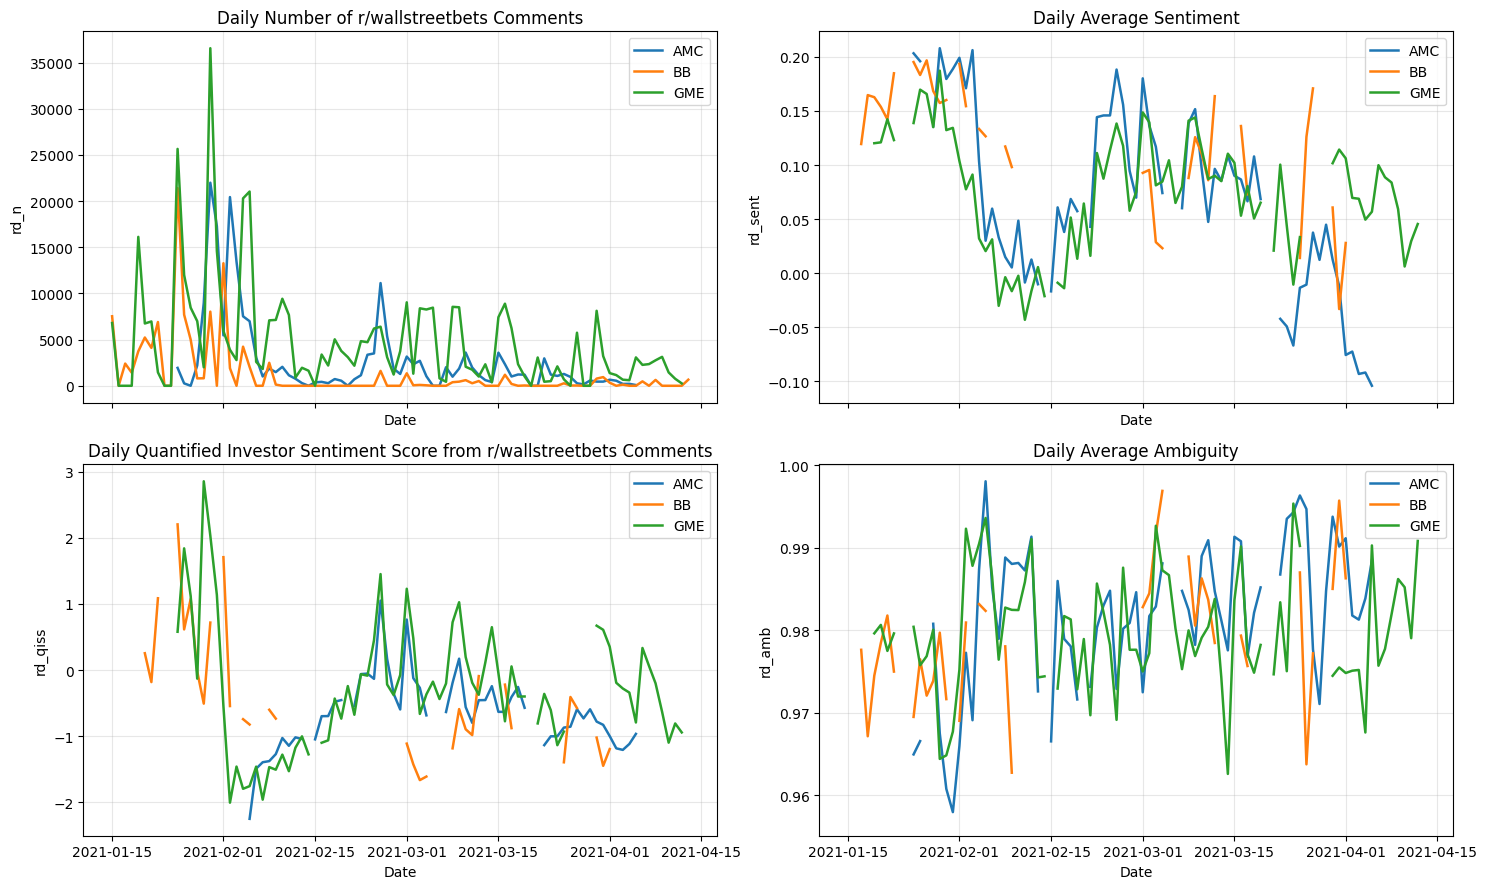

In [ ]:
## Daily Reddit
weekly_rd = plot_coverage(
    red,
    freq="D",
    start="2021-1-15",
    end="2021-4-15",
    columns=["rd_n",  "rd_sent", "rd_qiss", "rd_amb"]
)

## B: Get the Financial

In [ ]:
## Price
px = pd.read_csv(os.path.join(DATA_DIR, "prices_gme_amc_bb.csv"), header=[0, 1], index_col=0, skiprows=[2])
px.index = pd.to_datetime(px.index); px.index.name = "date"
P = px.stack(level=1, future_stack=True).reset_index().rename(columns={"level_1": "ticker", "Ticker": "ticker"})
P.columns = [c.lower().replace(" ", "_") for c in P.columns]
Praw = P.dropna(subset=["adj_close", "high", "low", "volume"]).query("volume > 0").sort_values(["ticker", "date"]).reset_index(drop=True)
print(Praw.columns)

Index(['date', 'ticker', 'adj_close', 'close', 'high', 'low', 'open', 'volume'], dtype='object')


In [ ]:
def market_features(g):
    TRADING_DAYS = 252
    WEEK = 5  # trading days in "next week"

    g = g.copy()

    # A. Market direction
    g["ret"] = np.log(g.adj_close).diff()
    g["abs_ret"] = g.ret.abs()

    # B. Market volatility
    log_hl = np.log(g.high / g.low)
    log_co = np.log(g.adj_close / g.open)

    # Daily Parkinson volatility
    g["park"] = np.sqrt(log_hl**2 / (4 * np.log(2)))

    # Annualized Garman-Klass volatility
    gk = (
        0.5 * log_hl**2
        - (2 * np.log(2) - 1) * log_co**2
    )
    g["gk_vol"] = np.sqrt(gk.clip(lower=0) * TRADING_DAYS)

    # Annualized 5-day realized volatility
    g["rv_5d"] = (
        g.ret.rolling(5).std() * np.sqrt(TRADING_DAYS)
    )

    # C. Trading activity
    g["logvol"] = np.log(g.volume)

    # Abnormal volume relative to previous 20 trading days
    g["abn_logvol"] = (
        g.logvol - g.logvol.shift(1).rolling(20).mean()
    )

    # D. Next-day prediction targets
    g["y_ret"] = g.ret.shift(-1)
    g["y_abs_ret"] = g.abs_ret.shift(-1)
    g["y_park_vol"] = g.park.shift(-1) * np.sqrt(TRADING_DAYS)
    g["y_logvol_1d"] = g.logvol.shift(-1)

    return g

P = pd.concat([market_features(g) for _, g in Praw.groupby("ticker")], ignore_index=True)
print(P.groupby("ticker").date.agg(["min", "max", "count"]))
print(P.columns)

              min        max  count
ticker                             
AMC    2013-12-18 2023-12-29   2525
BB     2009-01-02 2023-12-29   3774
GME    2009-01-02 2023-12-29   3774
Index(['date', 'ticker', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'ret', 'abs_ret', 'park', 'gk_vol', 'rv_5d', 'logvol', 'abn_logvol', 'y_ret', 'y_abs_ret', 'y_park_vol',
       'y_logvol_1d'],
      dtype='object')


## Bb: Get the Financial Features

### Monthly Features (Running these sections will have impact on the section `C:Overlay`)

In [ ]:
# Plot frequency: 'D' = daily, 'W' = weekly, 'ME' = monthly
FREQ = 'ME'

# Plot date range
#START_DATE = '2020-01-01'
#END_DATE   = '2021-12-31'

START_DATE="2009-01-01"
END_DATE="2024-12-31"

# Prepare data
P['date'] = pd.to_datetime(P['date'])
P = P.sort_values(['ticker', 'date'])

# Filter date range
P_filtered = P[
    (P['date'] >= START_DATE) &
    (P['date'] <= END_DATE)
].copy()

# Resample data for plotting
def prepare_plot_data(df, freq):
    if freq == 'D':
        return df

    return (
        df.set_index('date')
          .groupby('ticker')
          .resample(freq)
          .mean(numeric_only=True) ##Take the mean if multiple days are merged into one entry
          .reset_index()
    )

P_plot = prepare_plot_data(P_filtered, FREQ)

tickers = sorted(P_plot['ticker'].unique())

print(P_plot.columns)

Index(['ticker', 'date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'ret', 'abs_ret', 'park', 'gk_vol', 'rv_5d', 'logvol', 'abn_logvol', 'y_ret', 'y_abs_ret', 'y_park_vol',
       'y_logvol_1d'],
      dtype='object')


#### Dump All Selected Financial Indicators

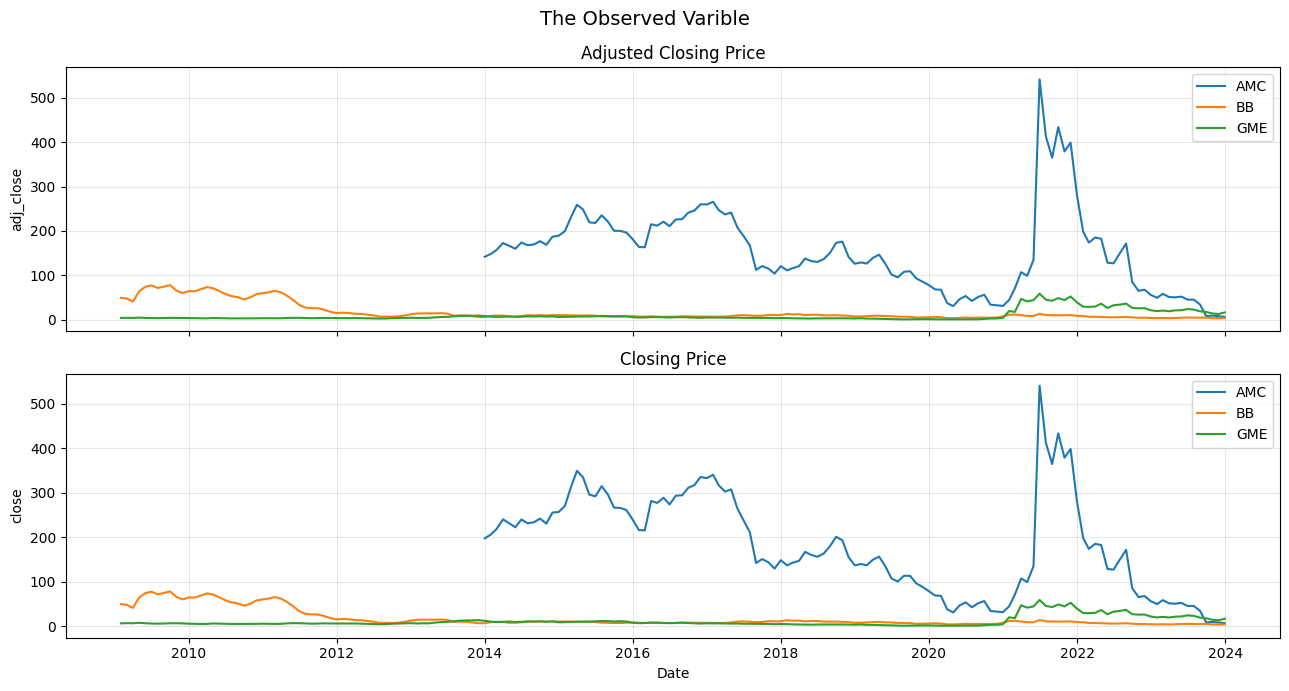

In [ ]:
metrics = ['adj_close','close', 'volume']

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for ax, metric in zip(axes, metrics):
    for ticker in tickers:
        data = P_plot[P_plot['ticker'] == ticker]
        ax.plot(data['date'], data[metric], label=ticker)

    ax.set_title(metric_titles[metric])
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle('The Observed Varible', fontsize=14)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

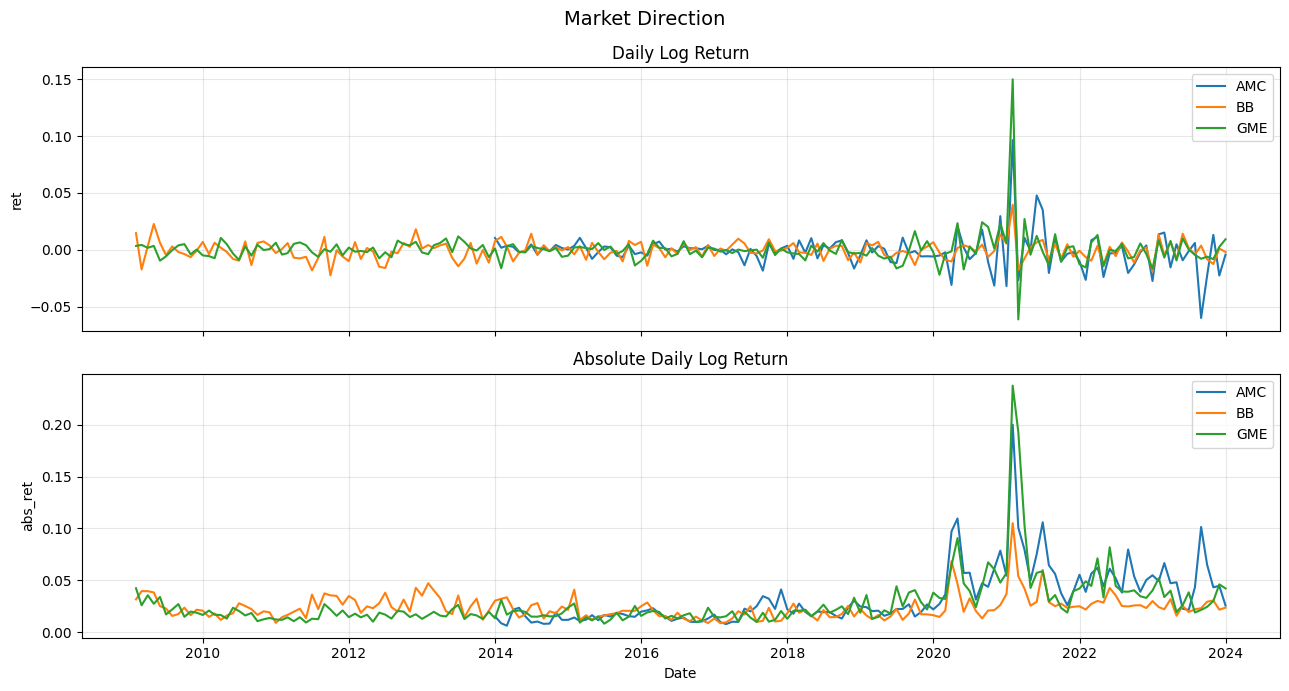

In [ ]:
metrics = ['ret', 'abs_ret']

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for ax, metric in zip(axes, metrics):
    for ticker in tickers:
        data = P_plot[P_plot['ticker'] == ticker]
        ax.plot(data['date'], data[metric], label=ticker)

    ax.set_title(metric_titles[metric])
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle('Market Direction', fontsize=14)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

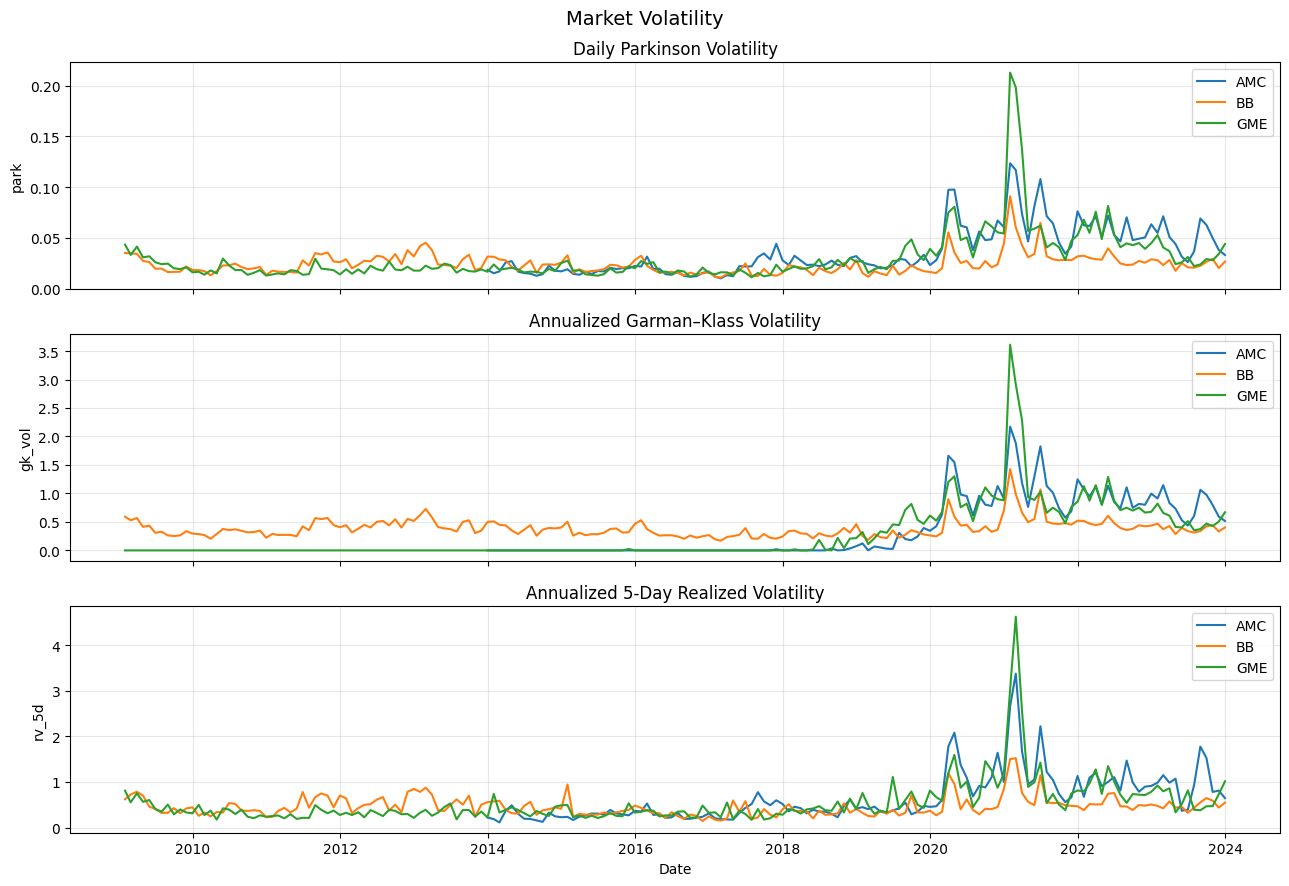

In [ ]:
metrics = ['park', 'gk_vol', 'rv_5d']

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

for ax, metric in zip(axes, metrics):
    for ticker in tickers:
        data = P_plot[P_plot['ticker'] == ticker]
        ax.plot(data['date'], data[metric], label=ticker)

    ax.set_title(metric_titles[metric])
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle('Market Volatility', fontsize=14)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

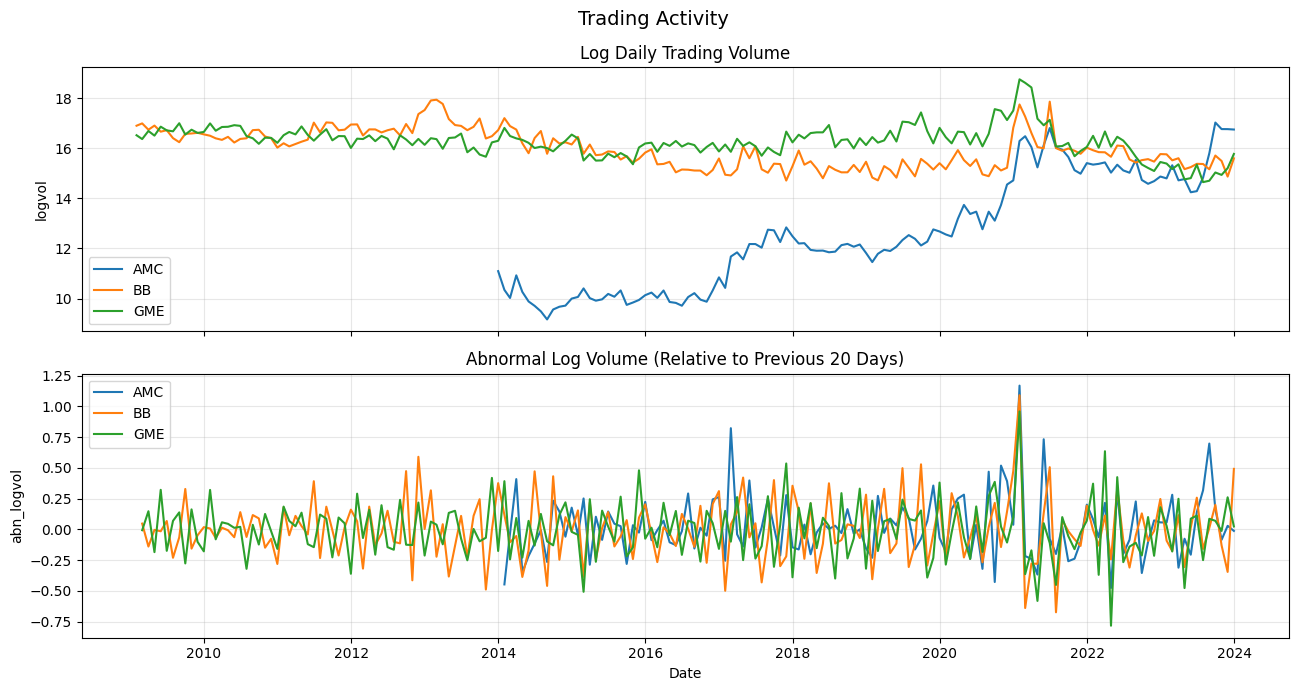

In [ ]:
metrics = ['logvol', 'abn_logvol']

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for ax, metric in zip(axes, metrics):
    for ticker in tickers:
        data = P_plot[P_plot['ticker'] == ticker]
        ax.plot(data['date'], data[metric], label=ticker)

    ax.set_title(metric_titles[metric])
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle('Trading Activity', fontsize=14)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

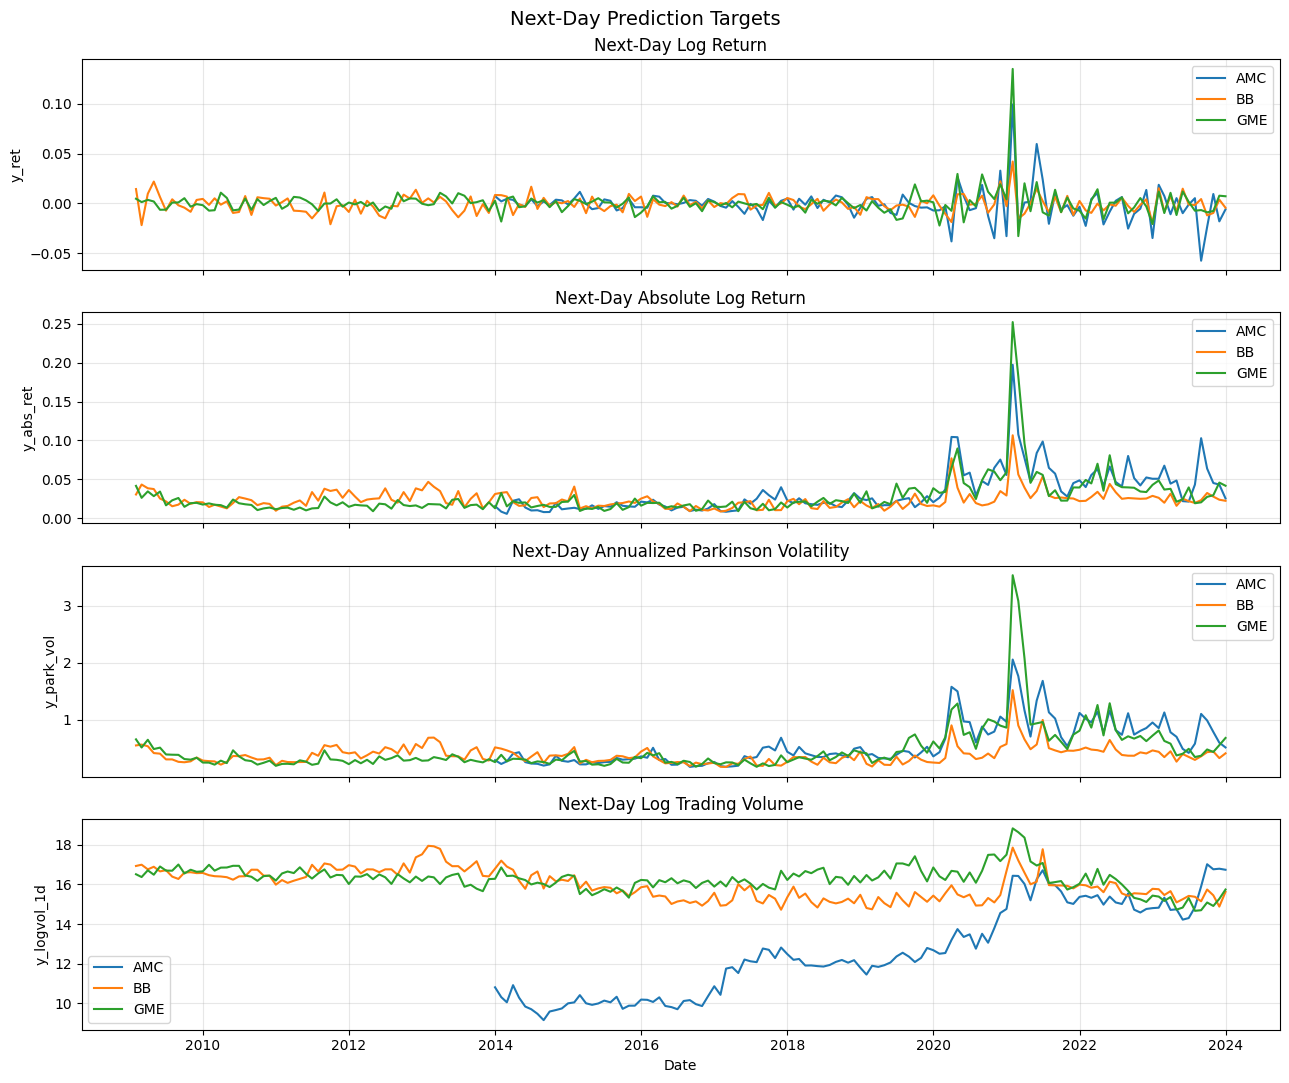

In [ ]:
metrics = [
    'y_ret',
    'y_abs_ret',
    'y_park_vol',
    'y_logvol_1d'
]

fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)

for ax, metric in zip(axes, metrics):
    for ticker in tickers:
        data = P_plot[P_plot['ticker'] == ticker]
        ax.plot(data['date'], data[metric], label=ticker)

    ax.set_title(metric_titles[metric])
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle('Next-Day Prediction Targets', fontsize=14)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

### Daily Feature (Running these sections will have impact on the section C:Overlay)

In [ ]:
# Plot frequency: 'D' = daily, 'W' = weekly, 'ME' = monthly
FREQ = 'D'

# Plot date range
START_DATE="2021-1-15"
END_DATE="2021-4-15"

# Prepare data
P['date'] = pd.to_datetime(P['date'])
P = P.sort_values(['ticker', 'date'])

# Filter date range
P_filtered = P[
    (P['date'] >= START_DATE) &
    (P['date'] <= END_DATE)
].copy()

# Resample data for plotting
def prepare_plot_data(df, freq):
    if freq == 'D':
        return df

    return (
        df.set_index('date')
          .groupby('ticker')
          .resample(freq)
          .mean(numeric_only=True) ##Take the mean if multiple days are merged into one entry
          .reset_index()
    )

P_plot = prepare_plot_data(P_filtered, FREQ)

tickers = sorted(P_plot['ticker'].unique())

print(P_plot.columns)

Index(['date', 'ticker', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'ret', 'abs_ret', 'park', 'gk_vol', 'rv_5d', 'logvol', 'abn_logvol', 'y_ret', 'y_abs_ret', 'y_park_vol',
       'y_logvol_1d'],
      dtype='object')


#### Plot dump

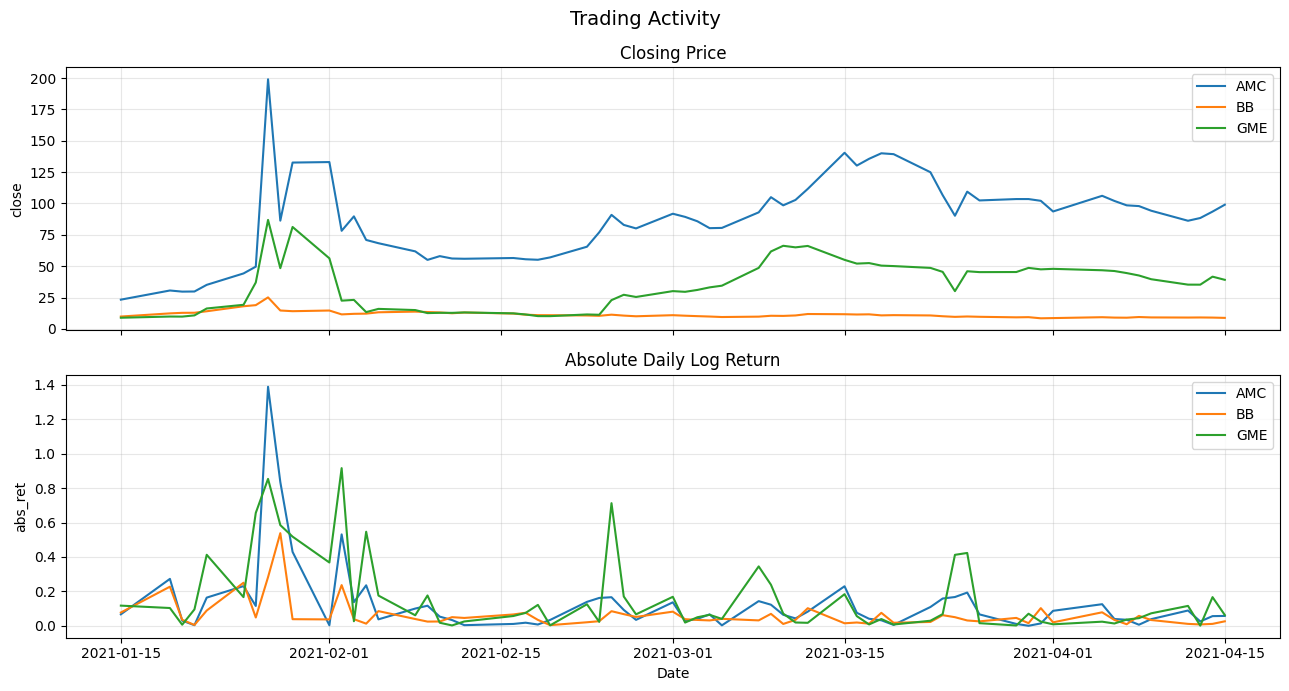

In [ ]:
metrics = ['close', 'abs_ret']

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for ax, metric in zip(axes, metrics):
    for ticker in tickers:
        data = P_plot[P_plot['ticker'] == ticker]
        ax.plot(data['date'], data[metric], label=ticker)

    ax.set_title(metric_titles[metric])
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle('Trading Activity', fontsize=14)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

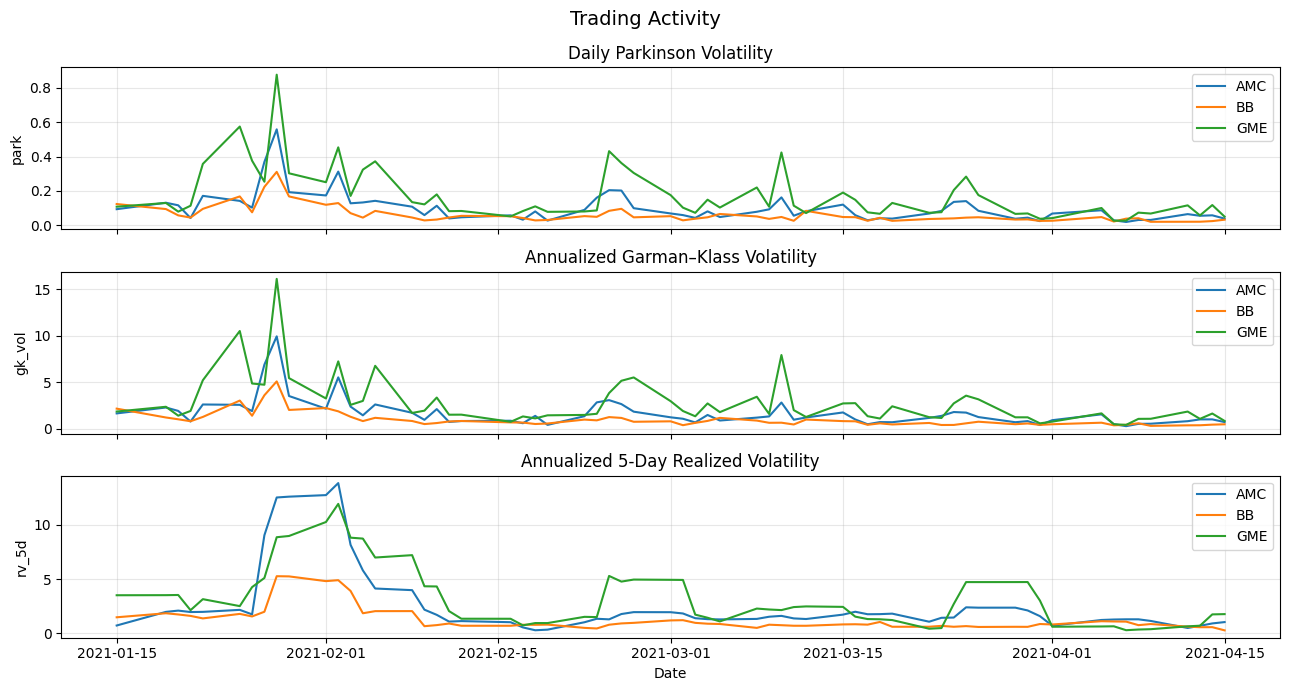

In [ ]:
metrics = ['park', 'gk_vol', 'rv_5d']

fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)

for ax, metric in zip(axes, metrics):
    for ticker in tickers:
        data = P_plot[P_plot['ticker'] == ticker]
        ax.plot(data['date'], data[metric], label=ticker)

    ax.set_title(metric_titles[metric])
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle('Trading Activity', fontsize=14)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

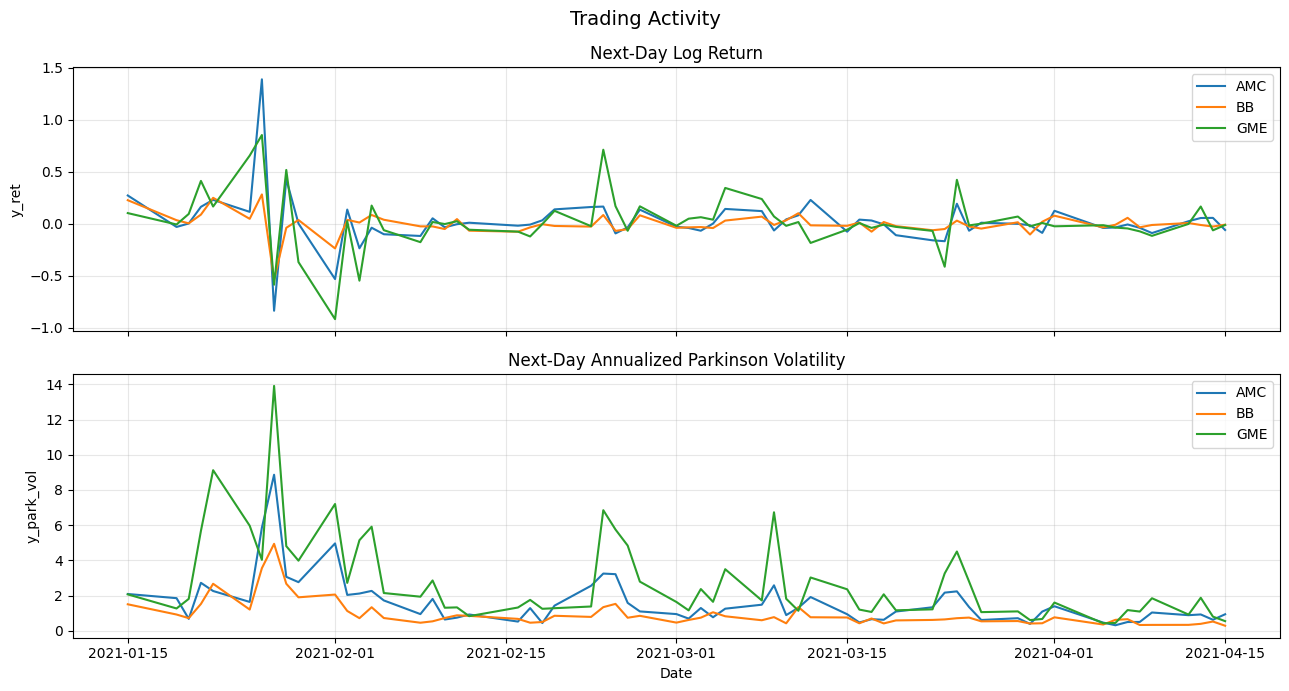

In [ ]:
metrics = ['y_ret', 'y_park_vol']

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for ax, metric in zip(axes, metrics):
    for ticker in tickers:
        data = P_plot[P_plot['ticker'] == ticker]
        ax.plot(data['date'], data[metric], label=ticker)

    ax.set_title(metric_titles[metric])
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle('Trading Activity', fontsize=14)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

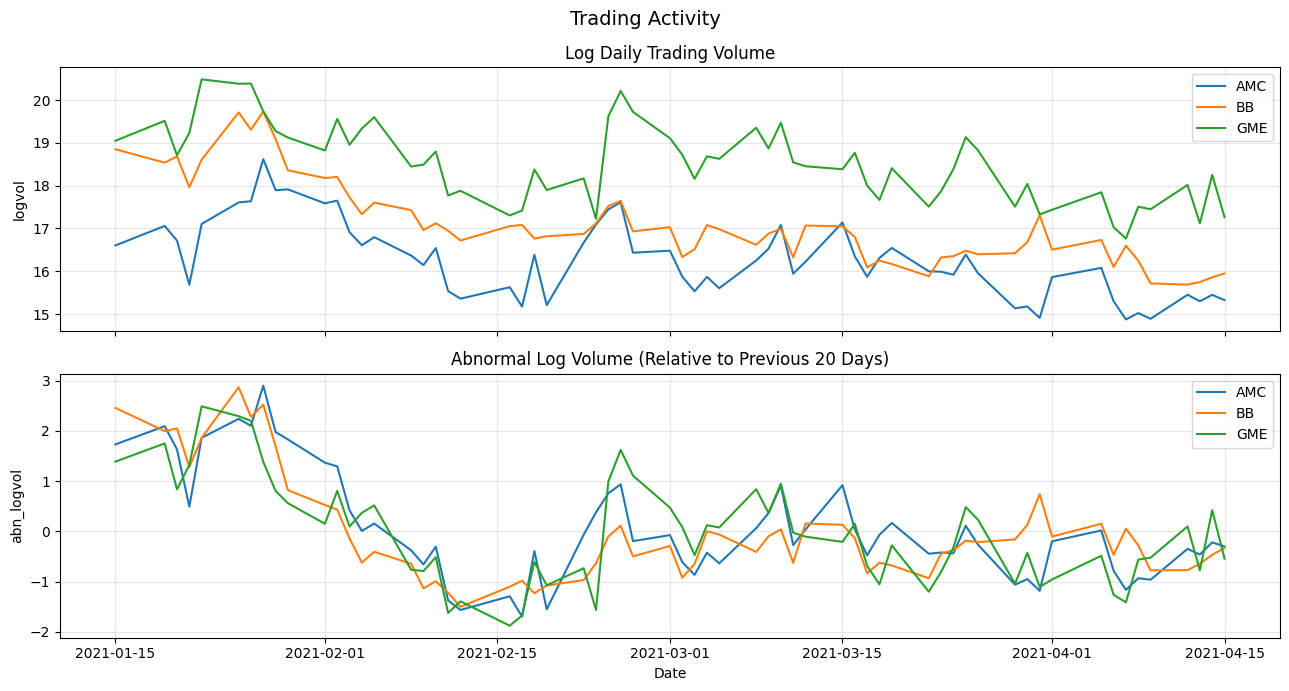

In [ ]:
metrics = ['logvol', 'abn_logvol']

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for ax, metric in zip(axes, metrics):
    for ticker in tickers:
        data = P_plot[P_plot['ticker'] == ticker]
        ax.plot(data['date'], data[metric], label=ticker)

    ax.set_title(metric_titles[metric])
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle('Trading Activity', fontsize=14)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

## C: Overlay Them

### Useful Functions

In [ ]:
def plot_news_market(
    news_df,
    market_df,
    ticker,
    sent_metric,
    market_metric,
    start_date=None,
    end_date=None,
    freq='D',
    figsize=(13, 5),
    alpha=0.5
):
    """
    Overlay a news/Reddit metric and a financial metric.

    News metric: bars on the right y-axis.
    Market metric: line on the left y-axis.
    """

    if freq not in ['D', 'W', 'ME']:
        raise ValueError("freq must be 'D', 'W', or 'ME'.")

    # Filter ticker and copy
    news = news_df[news_df['ticker'] == ticker].copy()
    market = market_df[market_df['ticker'] == ticker].copy()

    # Convert dates
    news['date'] = pd.to_datetime(news['date'])
    market['date'] = pd.to_datetime(market['date'])

    # Date filtering
    for df in [news, market]:
        if start_date is not None:
            df.drop(df[df['date'] < pd.Timestamp(start_date)].index, inplace=True)

        if end_date is not None:
            df.drop(df[df['date'] > pd.Timestamp(end_date)].index, inplace=True)

    # Frequency aggregation
    if freq != 'D':
        news = (
            news.set_index('date')[[sent_metric]]
                .resample(freq)
                .mean()
                .reset_index()
        )

        market = (
            market.set_index('date')[[market_metric]]
                  .resample(freq)
                  .mean()
                  .reset_index()
        )

    # Remove missing values
    news = news.dropna(subset=[sent_metric])
    market = market.dropna(subset=[market_metric])

    # Metric titles
    news_title = metric_titles.get(sent_metric, sent_metric)
    market_title = metric_titles.get(market_metric, market_metric)

    # Bar colors
    colors = [
        'green' if x > 0 else 'red' if x < 0 else 'gray'
        for x in news[sent_metric]
    ]

    # Plot
    fig, ax1 = plt.subplots(figsize=figsize)
    ax2 = ax1.twinx()

    # Market metric: left axis
    line, = ax1.plot(
        market['date'],
        market[market_metric],
        color='tab:blue',
        linewidth=1.5,
        label=market_title
    )

    # News metric: right axis
    bars = ax2.bar(
        news['date'],
        news[sent_metric],
        width={'D': 0.8, 'W': 5, 'ME': 20}[freq],
        color=colors,
        alpha=alpha,
        label=news_title
    )

    # Axis labels
    ax1.set_xlabel('Date')
    ax1.set_ylabel(market_title, color='tab:blue')
    ax2.set_ylabel(news_title)

    ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.grid(alpha=0.3)

    # Combined legend
    ax1.legend(
        [line, bars],
        [market_title, news_title],
        loc='upper left'
    )

    # Automatic title
    period = {'D': 'Daily', 'W': 'Weekly', 'ME': 'Monthly'}[freq]

    ax1.set_title(
        f'{ticker}: {period} {news_title} vs. {market_title}'
    )

    plt.tight_layout()
    plt.show()


def plot_news_market_save(
    news_df,
    market_df,
    ticker,
    sent_metric,
    market_metric,
    start_date=None,
    end_date=None,
    freq='D',
    figsize=(13, 5),
    alpha=0.5,
    save_dir=None,
    dpi=300
):
    """
    Overlay a news/Reddit metric and a financial metric.

    News metric: bars on the right y-axis.
    Market metric: line on the left y-axis.

    If save_dir is provided, save the plot as a PNG using
    the input parameters to generate the filename.
    """

    if freq not in ['D', 'W', 'ME']:
        raise ValueError("freq must be 'D', 'W', or 'ME'.")

    # Filter ticker and copy
    news = news_df[news_df['ticker'] == ticker].copy()
    market = market_df[market_df['ticker'] == ticker].copy()

    # Convert dates
    news['date'] = pd.to_datetime(news['date'])
    market['date'] = pd.to_datetime(market['date'])

    # Date filtering
    for df in [news, market]:
        if start_date is not None:
            df.drop(df[df['date'] < pd.Timestamp(start_date)].index, inplace=True)

        if end_date is not None:
            df.drop(df[df['date'] > pd.Timestamp(end_date)].index, inplace=True)

    # Frequency aggregation
    if freq != 'D':
        news = (
            news.set_index('date')[[sent_metric]]
                .resample(freq)
                .mean()
                .reset_index()
        )

        market = (
            market.set_index('date')[[market_metric]]
                  .resample(freq)
                  .mean()
                  .reset_index()
        )

    # Remove missing values
    news = news.dropna(subset=[sent_metric])
    market = market.dropna(subset=[market_metric])

    # Metric titles
    news_title = metric_titles.get(sent_metric, sent_metric)
    market_title = metric_titles.get(market_metric, market_metric)

    # Bar colors
    colors = [
        'green' if x > 0 else 'red' if x < 0 else 'gray'
        for x in news[sent_metric]
    ]

    # Plot
    fig, ax1 = plt.subplots(figsize=figsize)
    ax2 = ax1.twinx()

    # Market metric: left axis
    line, = ax1.plot(
        market['date'],
        market[market_metric],
        color='tab:blue',
        linewidth=1.5,
        label=market_title
    )

    # News metric: right axis
    bars = ax2.bar(
        news['date'],
        news[sent_metric],
        width={'D': 0.8, 'W': 5, 'ME': 20}[freq],
        color=colors,
        alpha=alpha,
        label=news_title
    )

    # Axis labels
    ax1.set_xlabel('Date')
    ax1.set_ylabel(market_title, color='tab:blue')
    ax2.set_ylabel(news_title)

    ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.grid(alpha=0.3)

    # Combined legend
    ax1.legend(
        [line, bars],
        [market_title, news_title],
        loc='upper left'
    )

    # Automatic title
    period = {'D': 'Daily', 'W': 'Weekly', 'ME': 'Monthly'}[freq]

    ax1.set_title(
        f'{ticker}: {period} {news_title} vs. {market_title}'
    )

    plt.tight_layout()

    # Save plot
    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)

        date_range = (
            f"{start_date or 'begin'}_to_{end_date or 'end'}"
        )

        filename = (
            f"{ticker}_{sent_metric}_vs_{market_metric}_"
            f"{freq}_{date_range}.png"
        )

        filepath = os.path.join(save_dir, filename)

        fig.savefig(filepath, dpi=dpi, bbox_inches='tight')
        print(f"Plot saved: {filepath}")

    #plt.show()
    plt.close(fig)

### Prepare data frames (news, reddit, yfiance)

Make sure the followings are defined: `news_b`, `red`, `P_plot` with the correct
`START_DATE` and `END_DATE`


We have a few options..
Three tickers: AMC, BB, GME

Two Sources: Reddit (weekly from "2009-01-01"to "2024-12-31"), News articles (monthly from "2009-01-01" to "2024-12-31")

Financial Indicators (14ish) & Sentiment Indicators (5 for each source)

--> This gives 420 combinations

### Make Plots

#### Monthly News Articles

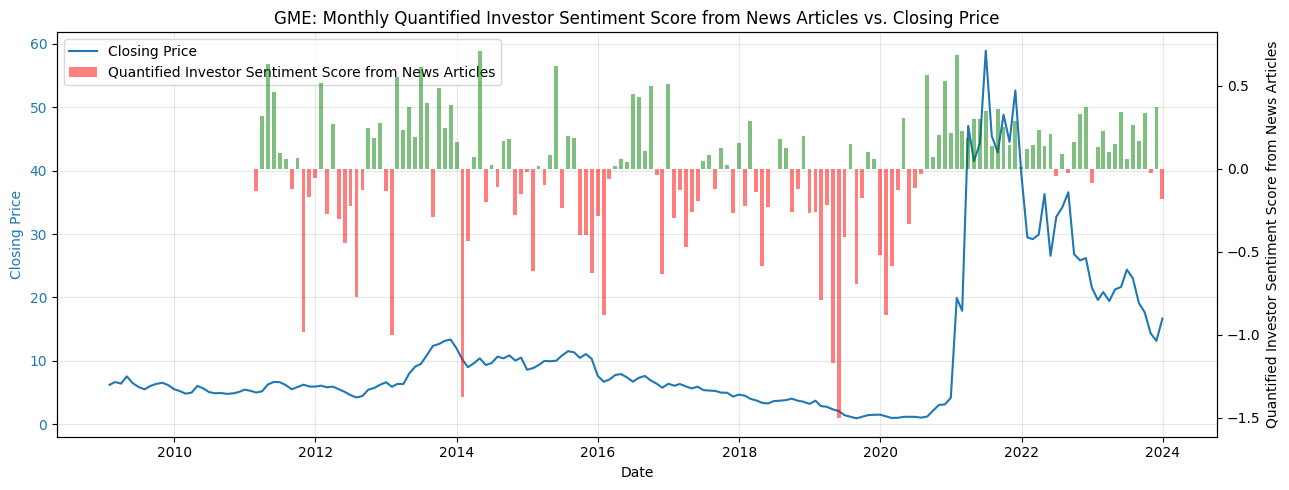

In [ ]:
# GME, sentiment, return
plot_news_market(
    news_b, P_plot,
    ticker='GME',
    sent_metric='nb_qiss',
    market_metric='close',
    freq='ME',
    start_date="2009-01-01",
    end_date="2024-12-31"
)

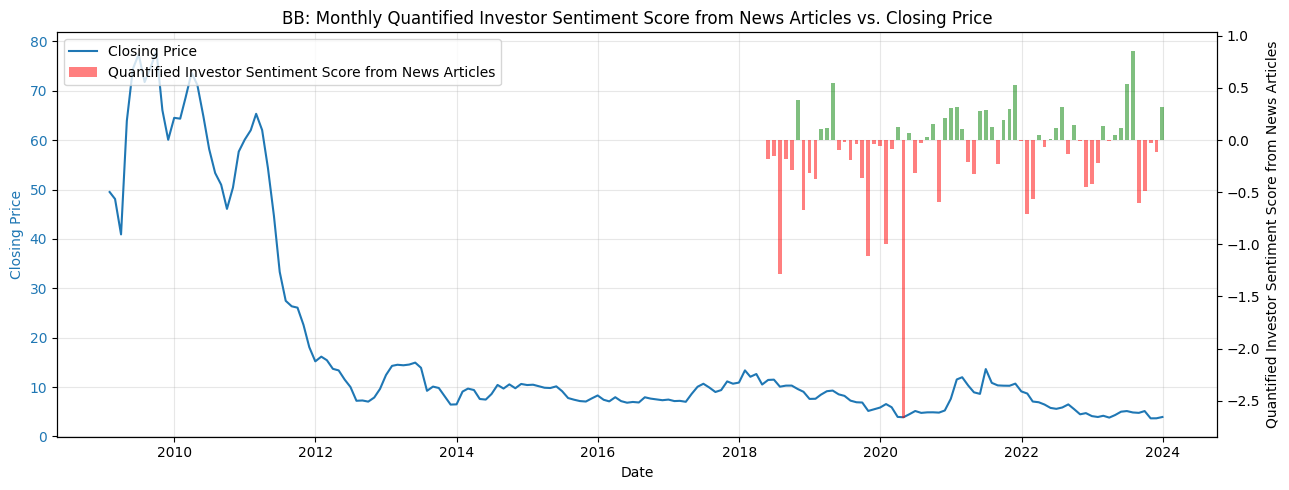

In [ ]:
# GME, sentiment, return
plot_news_market(
    news_b, P_plot,
    ticker='BB',
    sent_metric='nb_qiss',
    market_metric='close',
    freq='ME',
    start_date="2009-01-01",
    end_date="2024-12-31"
)

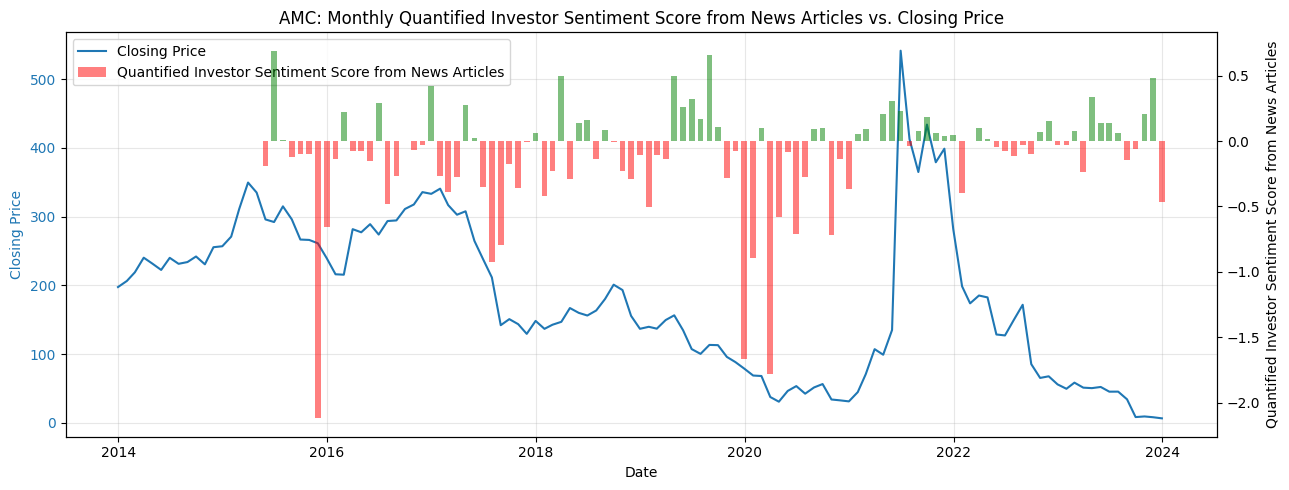

In [ ]:
# GME, sentiment, return
plot_news_market(
    news_b, P_plot,
    ticker='AMC',
    sent_metric='nb_qiss',
    market_metric='close',
    freq='ME',
    start_date="2009-01-01",
    end_date="2024-12-31"
)

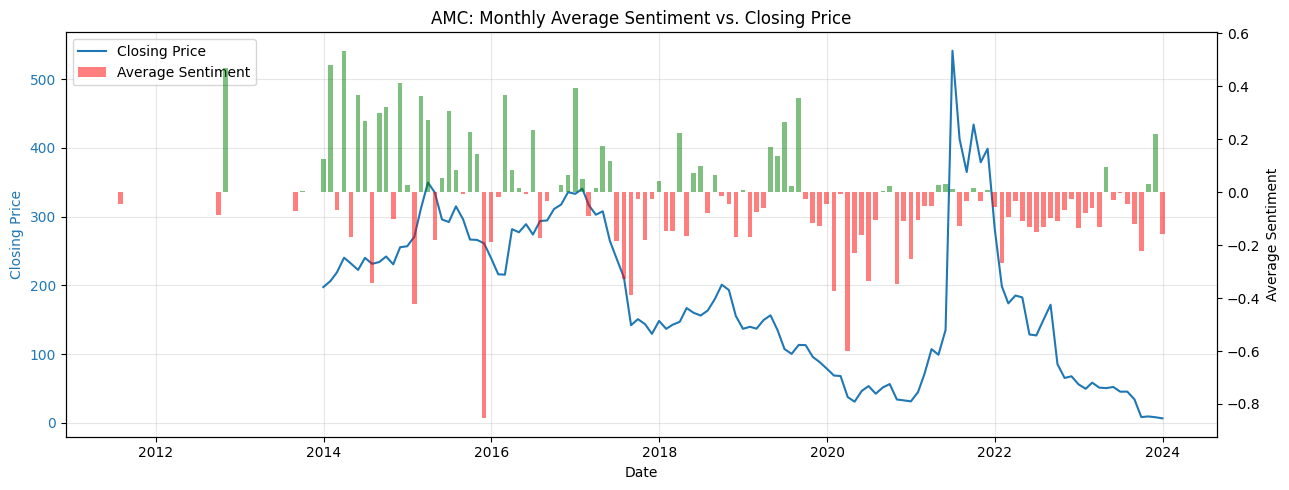

In [ ]:
# GME, sentiment, return
plot_news_market(
    news_b, P_plot,
    ticker='AMC',
    sent_metric='nb_sent',
    market_metric='close',
    freq='ME',
    start_date="2009-01-01",
    end_date="2024-12-31"
)

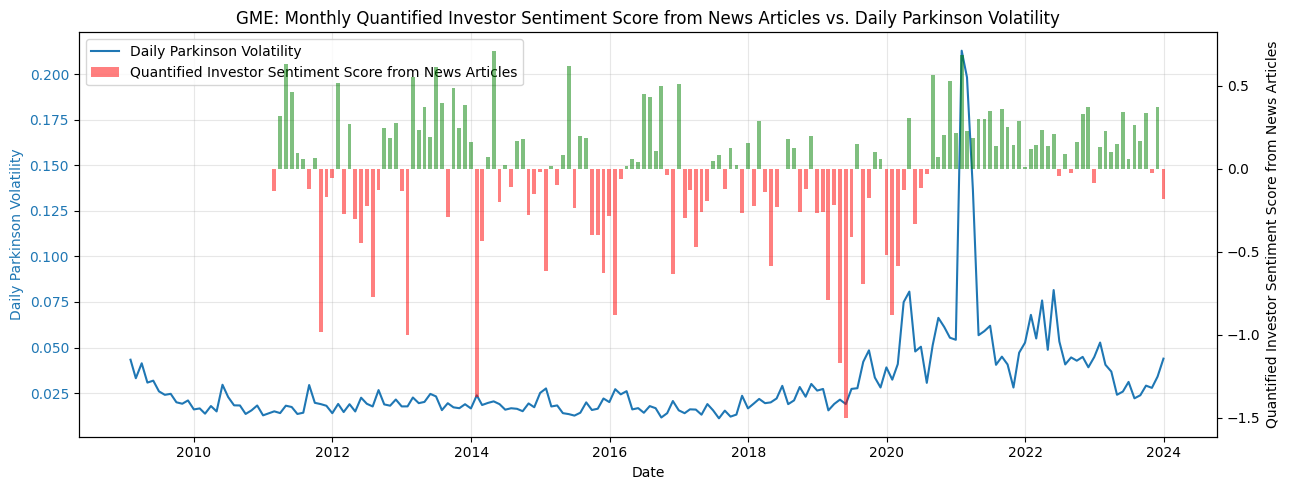

In [ ]:
# GME, qiss, volume
plot_news_market(
    news_b, P_plot,
    ticker='GME',
    sent_metric='nb_qiss',
    market_metric='park',
    freq='ME',
    start_date="2009-01-01",
    end_date="2024-12-31"
)

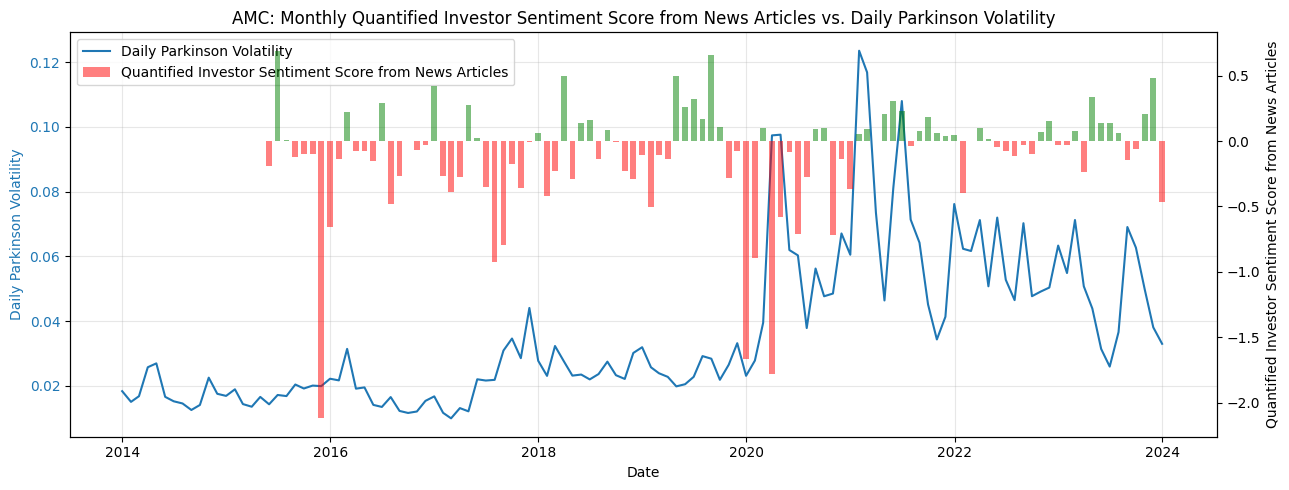

In [ ]:
# GME, qiss, volume
plot_news_market(
    news_b, P_plot,
    ticker='AMC',
    sent_metric='nb_qiss',
    market_metric='park',
    freq='ME',
    start_date="2009-01-01",
    end_date="2024-12-31"
)

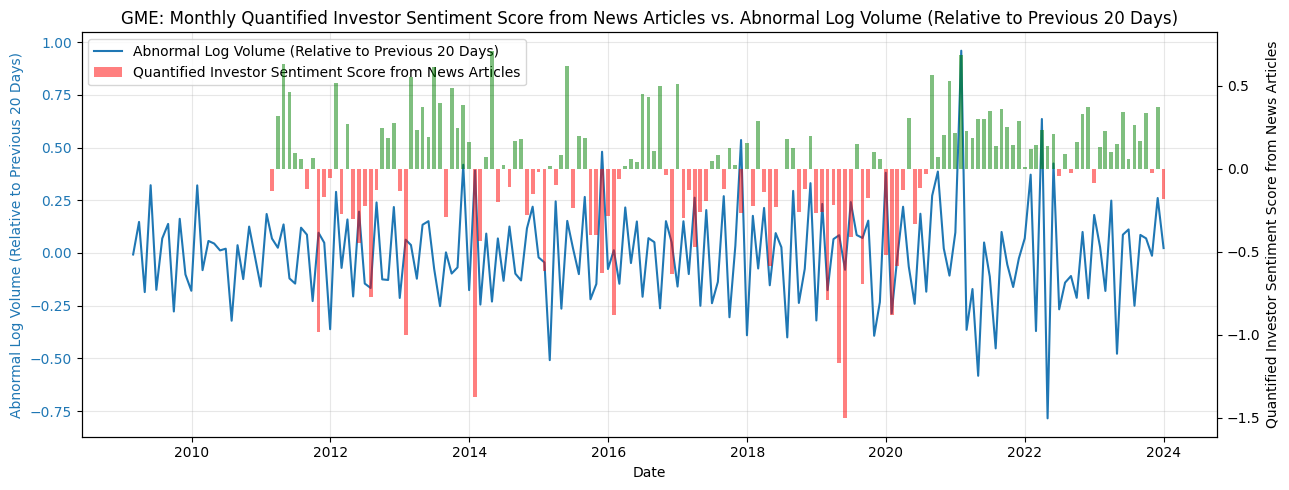

In [ ]:
# GME, qiss
plot_news_market(
    news_b, P_plot,
    ticker='GME',
    sent_metric='nb_qiss',
    market_metric='abn_logvol',
    freq='ME',
    start_date="2009-01-01",
    end_date="2024-12-31"
)

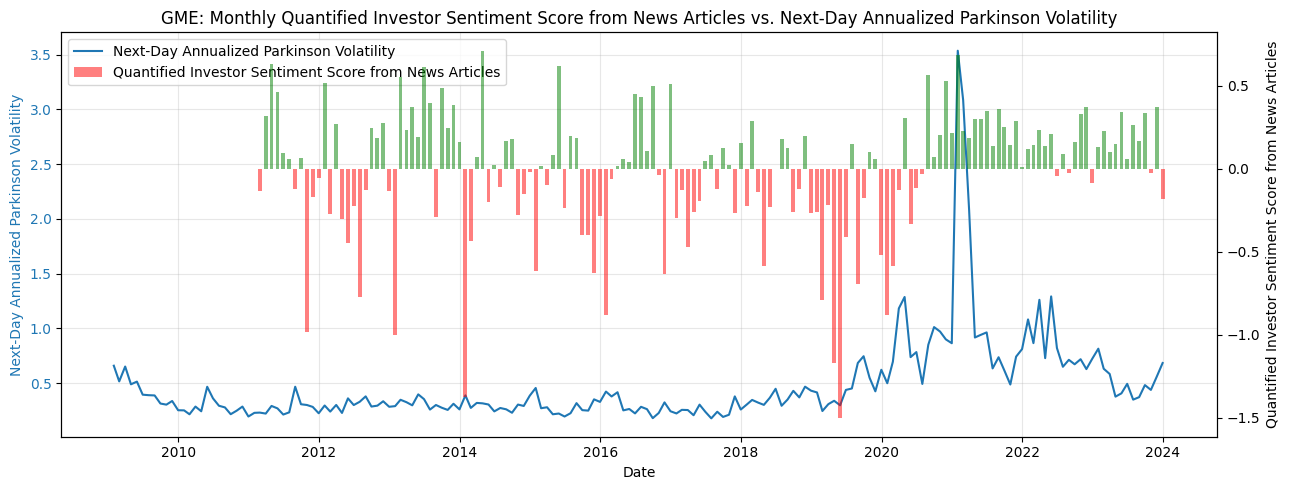

In [ ]:
# GME, qiss
plot_news_market(
    news_b, P_plot,
    ticker='GME',
    sent_metric='nb_qiss',
    market_metric='y_park_vol',
    freq='ME',
    start_date="2009-01-01",
    end_date="2024-12-31"
)

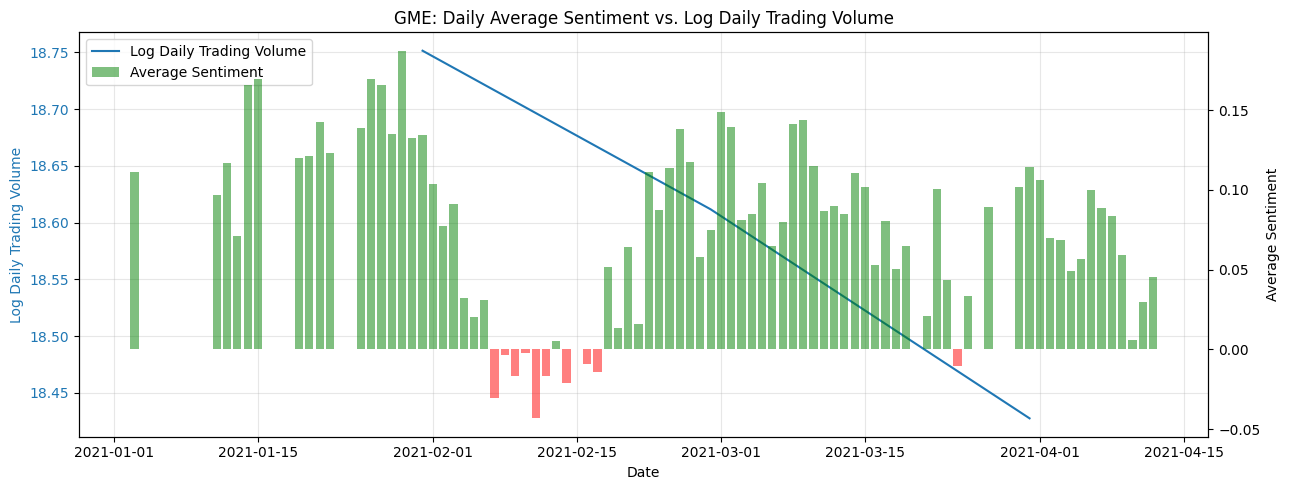

In [ ]:
plot_news_market(
    red, P_plot,
    ticker='GME',
    sent_metric='rd_sent',
    market_metric='logvol',
    freq='D',
    start_date="2021-01-01",
    end_date="2021-4-15"
)

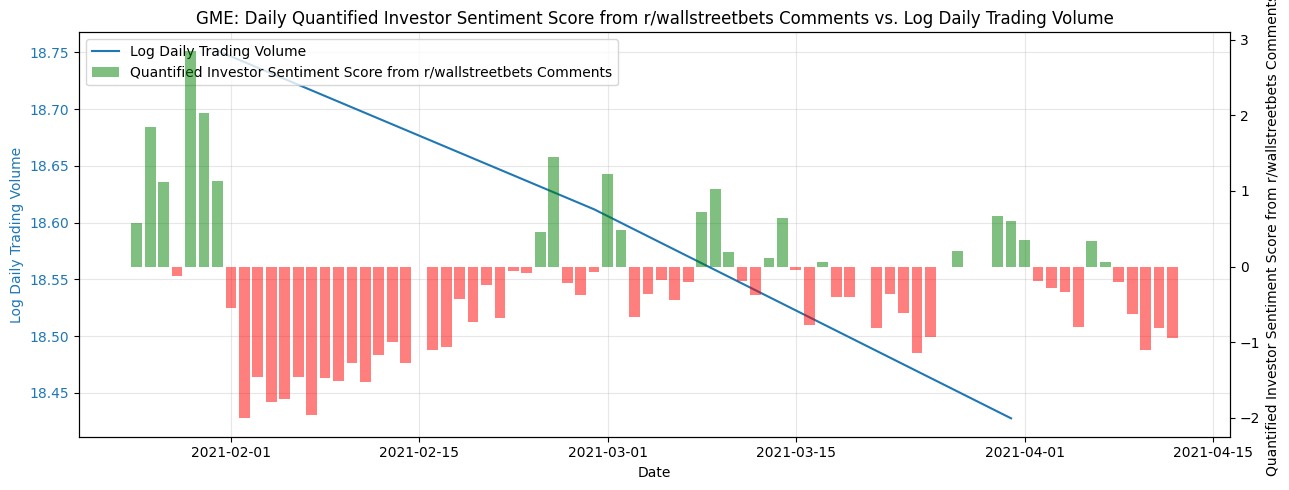

In [ ]:
plot_news_market(
    red, P_plot,
    ticker='GME',
    sent_metric='rd_qiss',
    market_metric='logvol',
    freq='D',
    start_date="2021-01-01",
    end_date="2021-4-15"
)

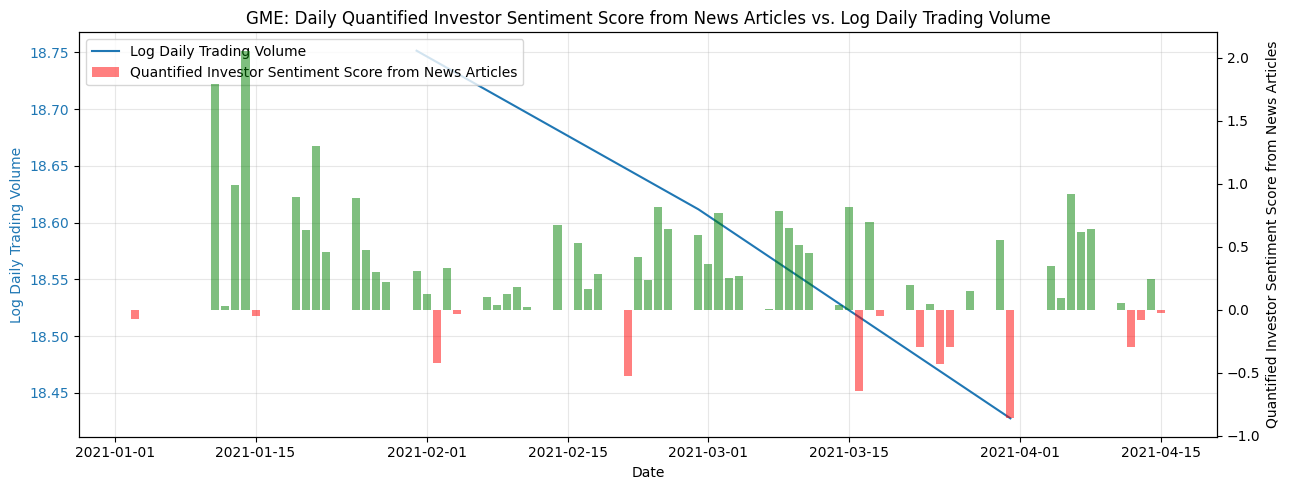

In [ ]:
plot_news_market(
    news_b, P_plot,
    ticker='GME',
    sent_metric='nb_qiss',
    market_metric='logvol',
    freq='D',
    start_date="2021-01-01",
    end_date="2021-4-15"
)

#### Daily News Articles

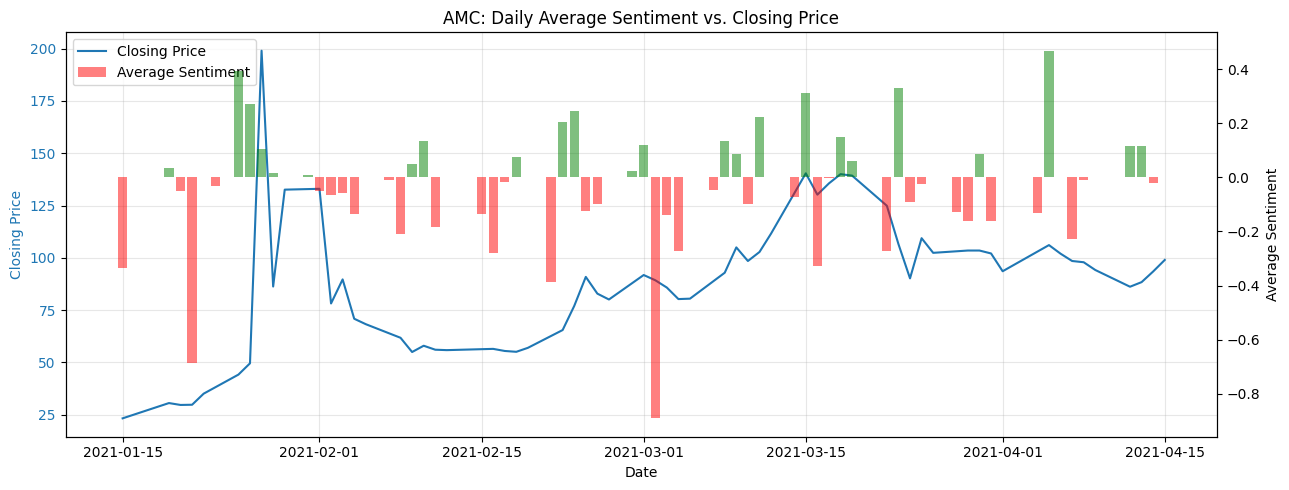

In [ ]:
#AMC, sentiment, return
plot_news_market(
    news_b, P_plot,
    ticker='AMC',
    sent_metric='nb_sent',
    market_metric='close',
    freq='D',
    start_date="2021-1-15",
    end_date="2021-4-15"
)

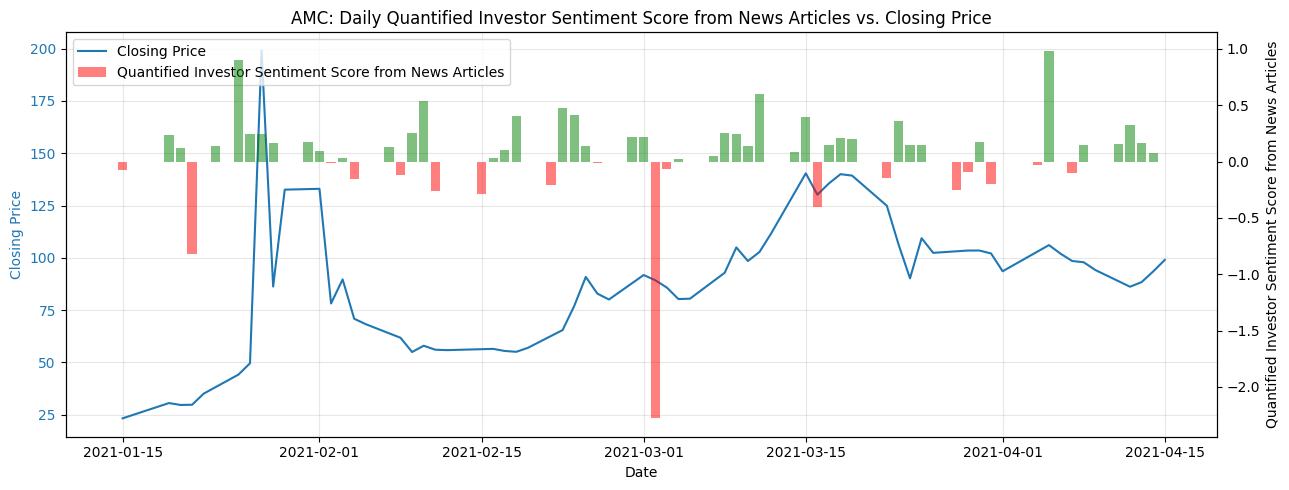

In [ ]:
# AMC, sentiment, return
plot_news_market(
    news_b, P_plot,
    ticker='AMC',
    sent_metric='nb_qiss',
    market_metric='close',
    freq='D',
    start_date="2021-1-15",
    end_date="2021-4-15"
)

#### Daily Reddit Comments

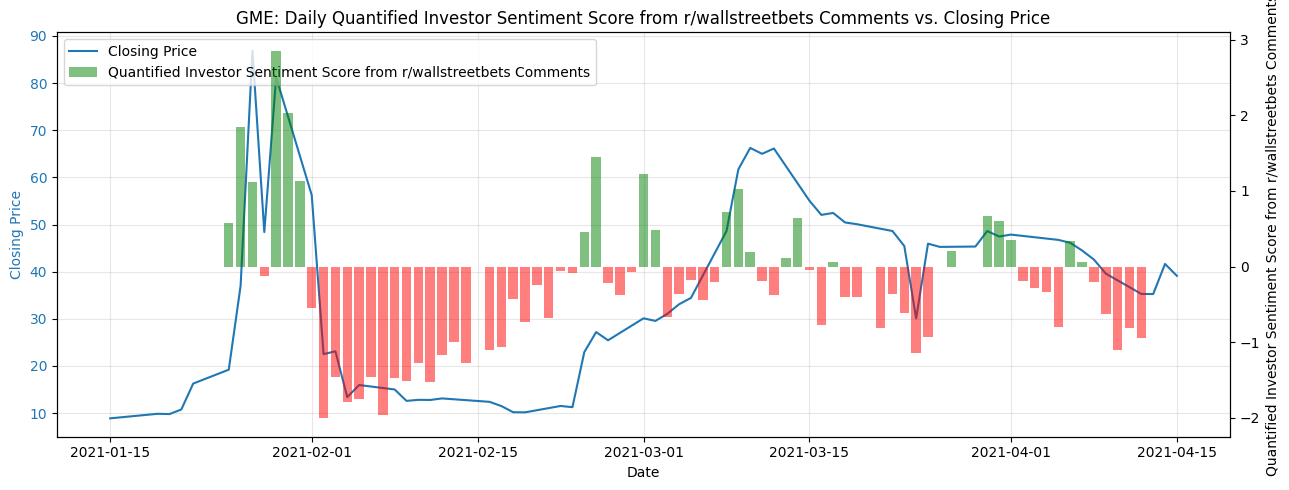

In [ ]:
# GME, sentiment
plot_news_market(
    red, P_plot,
    ticker='GME',
    sent_metric='rd_qiss',
    market_metric='close',
    freq='D',
    start_date="2021-1-15",
    end_date="2021-4-15"
)

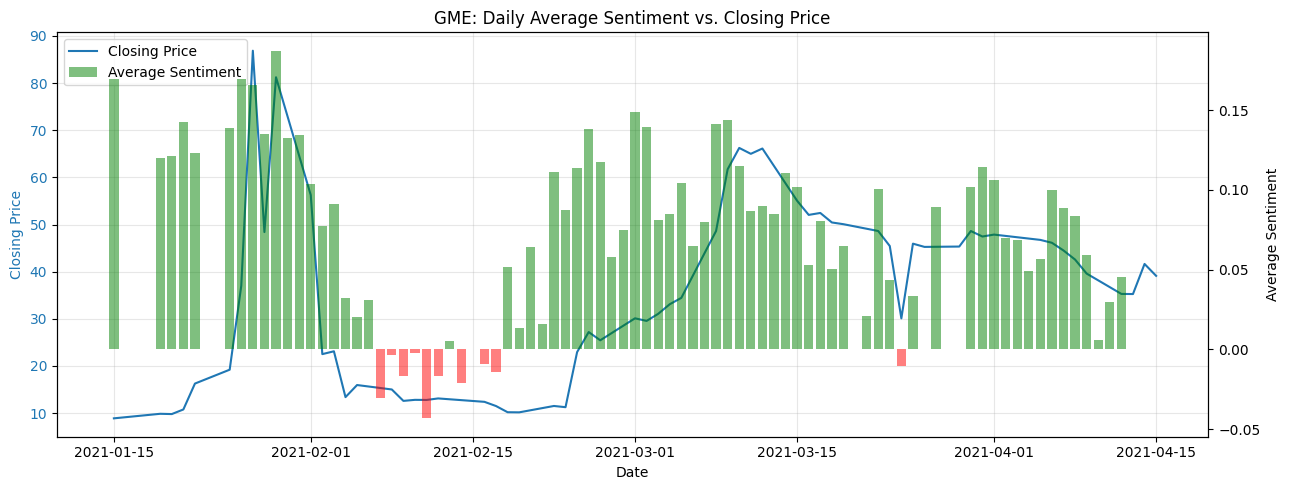

In [ ]:
# GME, sentiment
plot_news_market(
    red, P_plot,
    ticker='GME',
    sent_metric='rd_sent',
    market_metric='close',
    freq='D',
    start_date="2021-1-15",
    end_date="2021-4-15"
)

#### Daily Everything Loop

In [ ]:
## define the path to save plots
from itertools import product

SAVEPATH = os.path.join(PROJECT_DIR, "Plots")

Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_rd_sent_vs_park_W_2021-01-01_to_2021-12-31.png


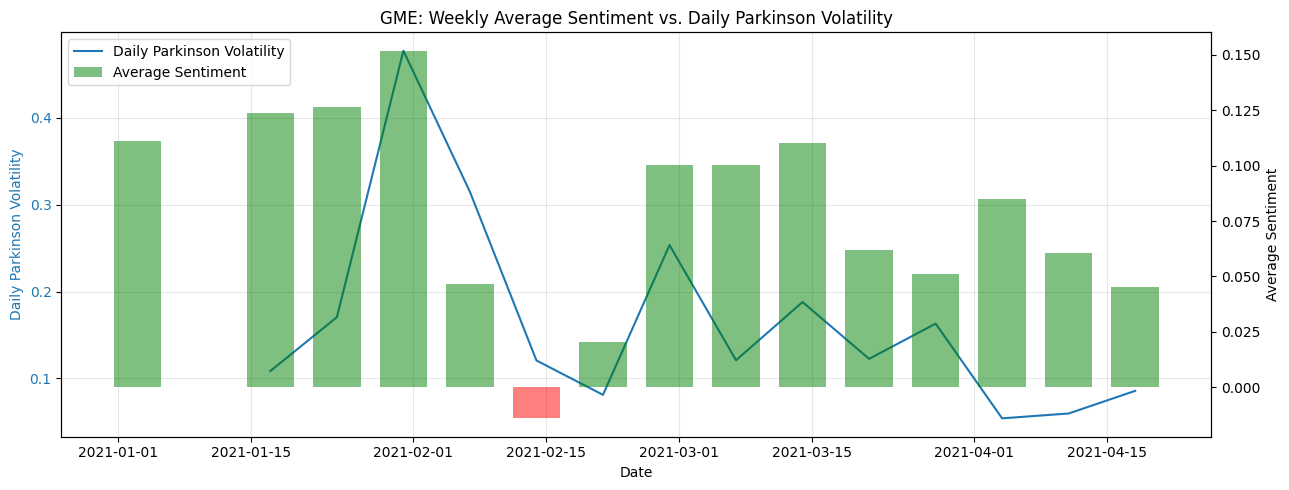

In [ ]:
# reddit
plot_news_market_save(
    red, P_plot,
    ticker='GME',
    sent_metric='rd_sent',
    market_metric='park',
    start_date="2021-1-15",
    end_date="2021-4-15"
    freq='D',
    save_dir=SAVEPATH
)

In [ ]:
# loop news plots
# reddit
plot_news_market_save(
    news_b, P_plot,
    ticker='GME',
    sent_metric='nb_sent',
    market_metric='park',
    start_date="2021-1-15",
    end_date="2021-4-15"
    freq='D',
    save_dir=SAVEPATH
)

In [ ]:
# news
tickers = ['GME', 'BB', 'AMC']

sent_metrics = ['nb_sent',  'nb_qiss']

market_metrics = [
    'adj_close', 'close', 'volume', 'ret', 'abs_ret',
    'park', 'gk_vol', 'rv_5d', 'logvol', 'abn_logvol',
    'y_ret', 'y_abs_ret', 'y_park_vol', 'y_logvol_1d'
]

# Generate all combinations
combinations = list(product(tickers, sent_metrics, market_metrics))

print(f"Total plots: {len(combinations)}")

# Generate and save plots
for ticker, sent_metric, market_metric in combinations:

    plot_news_market_save(
        news_b,
        P_plot,
        ticker=ticker,
        sent_metric=sent_metric,
        market_metric=market_metric,
        start_date="2021-1-15",
        end_date="2021-4-15",
        freq='D',
        save_dir=SAVEPATH
    )

print("All plots generated and saved.")

Total plots: 84
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_nb_sent_vs_adj_close_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_nb_sent_vs_close_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_nb_sent_vs_volume_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_nb_sent_vs_ret_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_nb_sent_vs_abs_ret_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_nb_sent_vs_park_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_nb_sent_vs_gk_vol_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_nb_sent_vs_rv_5d_D_2021-1-15_to_2

In [ ]:
# reddit
tickers = ['GME', 'BB', 'AMC']

sent_metrics = [
     'rd_sent', 'rd_qiss'
]

market_metrics = [
    'adj_close', 'close', 'volume', 'ret', 'abs_ret',
    'park', 'gk_vol', 'rv_5d', 'logvol', 'abn_logvol',
    'y_ret', 'y_abs_ret', 'y_park_vol', 'y_logvol_1d'
]
# Generate all combinations
combinations = list(product(tickers, sent_metrics, market_metrics))

print(f"Total plots: {len(combinations)}")

# Generate and save plots
for ticker, sent_metric, market_metric in combinations:

    plot_news_market_save(
        red,
        P_plot,
        ticker=ticker,
        sent_metric=sent_metric,
        market_metric=market_metric,
        start_date="2021-1-15",
        end_date="2021-4-15",
        freq='D',
        save_dir=SAVEPATH
    )

print("All plots generated and saved.")

Total plots: 84
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_rd_sent_vs_adj_close_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_rd_sent_vs_close_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_rd_sent_vs_volume_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_rd_sent_vs_ret_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_rd_sent_vs_abs_ret_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_rd_sent_vs_park_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_rd_sent_vs_gk_vol_D_2021-1-15_to_2021-4-15.png
Plot saved: /content/drive/MyDrive/Colab Notebooks/dl-quant_project/Plots/GME_rd_sent_vs_rv_5d_D_2021-1-15_to_2